# Project 3. 최종 모델 비교 (베이스라인 · ARIMA · SARIMA · 글로벌 MLP · Chronos-2 공변량 8종)

## 1. 목적과 구성
2023~2024년을 학습기간, 2025년을 테스트기간으로 **14일 rolling-origin 백테스트**를 수행해 모델을 같은 조건에서 비교하고, 선정된 모델을 2023~2025년 전체로 다시 학습해 **2026-01-01~01-14 개소별 방문객**을 예측합니다. 기존 노트북의 전처리, 개소 분류, 지표 함수, Chronos-2 실행 방식, ARIMA/SARIMA·MLP 설정을 재사용했고 기존 파일은 수정하지 않았습니다.

**비교 모델: 12개 비교안(실행 결과 14개)** — 베이스라인 3종은 하나의 모델군(비교안 1)으로 묶어 보고하되 코드에서는 고유 모델명으로 각각 실행합니다.

| 비교안 | 모델명(`model_id`) | 설명 |
|---:|---|---|
| 1 | `baseline_naive` / `baseline_seasonal_naive` / `baseline_mean7` | 나이브(직전 관측값) / 계절 나이브(7일 전 동일 요일) / 직전 7일 평균 |
| 2 | `arima` | 개소·타깃별 ARIMA (ADF로 d, AIC로 p·q 선택) |
| 3 | `sarima` | 개소·타깃별 SARIMA (주간 계절주기 7일) |
| 4 | `mlp_global` | 모든 개소가 공유하는 단순 MLP (개소·유형·요일·월 원핫, log1p) — 날짜·개소 정보만 사용 |
| 5 | `chronos_zero` | Chronos-2 제로샷 |
| 6 | `chronos_holiday` | + 한국 공휴일 |
| 7 | `chronos_weather` | + 강수 피처 블록(`rain_prob`, `heavy_prob`, `after_heavy_prob`) |
| 8 | `chronos_free` | + 무료개방 |
| 9 | `chronos_holiday_weather` | + 공휴일 + 강수 피처 블록 |
| 10 | `chronos_holiday_free` | + 공휴일 + 무료개방 |
| 11 | `chronos_weather_free` | + 강수 피처 블록 + 무료개방 |
| 12 | `chronos_holiday_weather_free` | + 공휴일 + 강수 피처 블록 + 무료개방 |

기온을 쓰는 `chronos_wx`와 개별 강수 변형 모델(`chronos_cal_rain` 등)은 만들지 않았고, 글로벌 MLP에는 공휴일·강수·무료개방을 넣지 않았습니다.

## 2. 피처 정의
- **한국 공휴일** `is_holiday`: 기존 한국 달력(2023~2025 `calendar_kr_cn_jp_2023_2025_with_season.csv`, 2026 `calendar_kr_2026_global_with_season.csv`)의 법정·대체공휴일 정의 그대로. 중국·일본·대만 공휴일은 쓰지 않습니다.
- **강수 피처 블록** (개소·월별 과거 발생확률, 하나의 블록으로 통일): 일 강수량에서 `rain = precip_mm ≥ 1`, `heavy = precip_mm ≥ 10`, `after_heavy = 전날 heavy이고 당일 precip_mm < 1`(같은 개소의 전날 기준)을 만든 뒤 **같은 개소·같은 월의 평균**을 `rain_prob`, `heavy_prob`, `after_heavy_prob`로 사용합니다. 2025년 테스트용 확률은 **2023~2024년 날씨만**, 2026년 예측용 확률은 **2023~2025년 날씨만**으로 계산하며 학습 행과 예측 행이 같은 확률표를 씁니다. 실제 일별 강수는 모델 입력이 아니고 **주간 조건 분류(평가 그룹)에만** 씁니다. 개별 날짜의 비를 맞히는 예보가 아니라 해당 개소·월의 과거 강수 위험을 나타냅니다.
- **무료개방** `free_open`: ① **문화가 있는 날** = 매월 마지막 수요일(해당 월의 모든 수요일 중 가장 늦은 날) ② **설 연휴** = 기존 달력에서 설 연휴로 분류된 날(설날 전날·당일·다음날·대체휴일, `seollal_offset`가 있는 공휴일). 2025년과 2026년에 같은 규칙을 적용하며 행사성·비정기 무료개방은 포함하지 않습니다. 적용 개소 범위와 근거는 섹션 4의 설정값(`FREE_OPEN_SITE_SCOPE`)과 섹션 5의 출력에 있습니다.

## 3. 평가 설계
- 학습 2023-01-01~2024-12-31, 테스트 2025-01-01~2025-12-31(14일 단위 27개 구간), 개소별 예측. **기존 노트북과 같은 구조**로 `domestic`과 `foreign_total`을 따로 예측해 `total = domestic + foreign_total`로 합산하고 `total`을 1차 평가 대상으로 합니다(내국인·외국인 결과도 CSV에 포함). 휴관일(목표 NaN)은 학습·평가에서 제외합니다.
- **지표는 기존 다섯 가지만**: WAPE(1순위), RelMAE(계절 나이브 대비, 보조), 적중률, 포함률, 평균 구간 길이. 새 지표·종합점수는 만들지 않습니다.
- **모든 모델에 같은 예측구간**: 기존 Chronos-2 비교의 구간 `[q10, q90]`은 명목 포함률 80%이므로 모든 모델에 **목표 포함률 80%의 split conformal 구간**을 적용합니다. 보정 오차는 학습기간(2024-07-03~2024-12-31, 13개 rolling 구간)의 개소별 오차만 사용하고 2025년 실제값은 쓰지 않습니다(MLP는 2024-07-02까지만 학습한 모델로 보정). 점 예측값은 바꾸지 않고 하한은 0 미만이 되지 않게 합니다. **적중률**은 기존 정의(실제 ≤ q80)를 같은 방식으로 적용해 모델별 conformal 80% 상위 한계(q80 상당)를 씁니다.
- 모델 순위: WAPE → RelMAE → 적중률(목표 0.8과의 거리) → 포함률·구간 길이 균형. WAPE 차이가 0.1%p(프로젝트의 기존 동률 기준) 이내이면 *유사한 수준*으로 보고 다음 기준으로 판단합니다.

## 4. 설정

In [1]:
import hashlib
import importlib.util
import inspect
import json
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import Markdown, display
from joblib.externals.loky import get_reusable_executor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

# ---------- 실행 모드 ----------
FAST_DEBUG = os.environ.get("FINAL_FAST_DEBUG", "0") == "1"     # 1이면 3개 개소·일부 구간만 빠르게 점검 (결과는 *_debug 폴더에 저장)
FORCE_RERUN = False       # True면 저장된 예측(cache)을 무시하고 처음부터 다시 실행
N_JOBS = int(os.environ.get("FINAL_N_JOBS", "4"))                # ARIMA/SARIMA 병렬 작업 수

# ---------- 경로 (프로젝트 루트 기준 상대경로) ----------
DATA_DIR = Path("dataset")
PATHS = dict(visitors=DATA_DIR / "heritage_visitors_daily_preprocessed_2023_2025.csv",
             sites=DATA_DIR / "sites.csv",
             calendar_hist=DATA_DIR / "calendar_kr_cn_jp_2023_2025_with_season.csv",
             calendar_2026=DATA_DIR / "calendar_kr_2026_global_with_season.csv",
             weather=DATA_DIR / "weather_daily.parquet",
             reference_baselines=Path("outputs") / "project3_baseline_mlp" / "predictions" / "all_model_predictions_2025.csv",     # 기존 프로젝트 베이스라인 저장 결과 (구현 검증용)
             earlier_chronos_zero=Path("cache") / "chronos2_weather_holiday_comparison" / "raw_M1_ZeroShot.csv",                 # 같은 설정의 기존 Chronos-2 제로샷 (교차 검증용)
             earlier_chronos_holiday=Path("cache") / "chronos2_weather_holiday_comparison" / "raw_M3_ZeroShot_Holiday.csv")
SUFFIX = "_debug" if FAST_DEBUG else ""
OUTPUT_DIR = Path("outputs") / f"final_model_comparison{SUFFIX}"
CACHE_DIR = Path("cache") / f"final_model_comparison{SUFFIX}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ---------- 기간·예측 ----------
HISTORY_START, TRAIN_END = pd.Timestamp("2023-01-01"), pd.Timestamp("2024-12-31")
TEST_START, TEST_END = pd.Timestamp("2025-01-01"), pd.Timestamp("2025-12-31")
FINAL_TRAIN_END = pd.Timestamp("2025-12-31")
FORECAST_START, FORECAST_END = pd.Timestamp("2026-01-01"), pd.Timestamp("2026-01-14")
HORIZON, N_FOLDS, SEED = 14, 27, 42
N_CAL_FOLDS = 13                         # 보정(calibration) 구간 수: 2024-07-03 ~ 2024-12-31 (테스트 구간과 같은 14일 격자)
TIMELINE = pd.date_range(HISTORY_START, FORECAST_END)
TARGETS = ["domestic", "foreign_total"]          # 개별 예측 대상, total = 합산
ALL_TARGETS = ["domestic", "foreign_total", "total"]
WEEKDAY_TO_NUMBER = {"월": 0, "화": 1, "수": 2, "목": 3, "금": 4, "토": 5, "일": 6}
GROUPS = ["궁", "종묘", "왕릉"]

# ---------- 예측구간·지표 ----------
COVERAGE_LEVEL = 0.8        # 기존 Chronos-2 비교의 [q10, q90] 구간의 명목 포함률(80%)과 같은 수준, 모든 모델에 동일 적용
MIN_CAL_ROWS = 10 if FAST_DEBUG else 30     # 개소별 보정 오차가 이보다 적으면 오류로 중단 (디버그는 보정 구간이 2개뿐)
TIE_TOLERANCE = 0.1         # %p: WAPE 차이가 이 값 이내면 '유사한 수준' (기존 프로젝트의 동률 기준)
LOW_N_WARNING = 30          # 관측치가 이보다 적은 조건은 '표본 적음(참고)' 표시
METRICS = ["WAPE", "RelMAE", "hit_rate", "coverage", "mean_interval_width"]

# ---------- 강수·무료개방 규칙 ----------
RAIN_MM, HEAVY_MM = 1.0, 10.0
FREE_OPEN_WEEKDAY = 2       # 수요일 → 매월 마지막 수요일(문화가 있는 날)
# 무료개방 적용 개소 범위: 프로젝트에 개소별 무료개방 적용표가 없어 다음 근거로 '전체 개소'로 둔다.
#  - 2023~2024년(학습기간) 방문객 자료에서 마지막 수요일의 무료 관람 비중이 23개 개소 모두 약 88% 이상(전체 평균 99%), 설 연휴 비중은 99% 이상 (섹션 5 출력)
#  - 적용 대상을 줄이려면 이 값을 개소 이름 리스트로 바꾸면 된다 (None = 전체 개소)
FREE_OPEN_SITE_SCOPE = None

# ---------- 모델 설정 (기존 프로젝트 재사용) ----------
SEASONAL_LAGS = (7, 14, 21, 28, 35, 42, 364)
BASELINE_BASES = {"baseline_naive": "Naive", "baseline_seasonal_naive": "Seasonal Naive", "baseline_mean7": "7-day Mean"}
REFERENCE_MODEL = "baseline_seasonal_naive"       # RelMAE 기준 모델
MLP_FEATURES = ["site", "group", "weekday", "month"]
MLP_PARAMS = dict(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=0.01, learning_rate_init=0.001,
                  batch_size=128, max_iter=500, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20)
SEASONAL_PERIOD, ADF_ALPHA, EXPLOSION_FACTOR = 7, 0.05, 3
P_RANGE, Q_RANGE = range(3), range(3)
SARIMA_SEASONAL_CANDIDATES = [(1, 1), (0, 1), (1, 0)]
FALLBACK_SOURCES = {"arima": "baseline_naive", "sarima": "baseline_seasonal_naive"}     # 사전 정의한 fallback
CHRONOS_MODEL_ID = "amazon/chronos-2"
QUANTILES, QUANTILE_COLUMNS = [0.1, 0.5, 0.8, 0.9], ["q10", "q50", "q80", "q90"]
FEATURE_VERSION = "v1-rainprob-freeopen"      # 공변량 정의를 바꾸면 올려서 cache를 무효화

HOLIDAY_FEATURES = ["is_holiday"]
WEATHER_FEATURES = ["rain_prob", "heavy_prob", "after_heavy_prob"]
FREE_FEATURES = ["free_open"]
ALL_COVARIATES = HOLIDAY_FEATURES + FREE_FEATURES + WEATHER_FEATURES

# (model_id, 한글명, 짧은 이름, 모델군, 종류, 공변량, 비교안 번호)
_CH = "Chronos-2"
MODEL_REGISTRY = [
    dict(id="baseline_naive", label="나이브", short="나이브", family="베이스라인", kind="baseline", covariates=[], item=1),
    dict(id="baseline_seasonal_naive", label="계절 나이브", short="계절\n나이브", family="베이스라인", kind="baseline", covariates=[], item=1),
    dict(id="baseline_mean7", label="직전 7일 평균", short="7일\n평균", family="베이스라인", kind="baseline", covariates=[], item=1),
    dict(id="arima", label="ARIMA", short="ARIMA", family="ARIMA", kind="stat", covariates=[], item=2),
    dict(id="sarima", label="SARIMA", short="SARIMA", family="SARIMA", kind="stat", covariates=[], item=3),
    dict(id="mlp_global", label="글로벌 MLP", short="글로벌\nMLP", family="글로벌 MLP", kind="mlp", covariates=[], item=4),
    dict(id="chronos_zero", label="Chronos-2 제로샷", short="C2\n제로샷", family=_CH, kind="chronos", covariates=[], item=5),
    dict(id="chronos_holiday", label="Chronos-2 제로샷 + 공휴일", short="C2\n+공휴일", family=_CH, kind="chronos", covariates=HOLIDAY_FEATURES, item=6),
    dict(id="chronos_weather", label="Chronos-2 제로샷 + 날씨", short="C2\n+날씨", family=_CH, kind="chronos", covariates=WEATHER_FEATURES, item=7),
    dict(id="chronos_free", label="Chronos-2 제로샷 + 무료개방", short="C2\n+무료", family=_CH, kind="chronos", covariates=FREE_FEATURES, item=8),
    dict(id="chronos_holiday_weather", label="Chronos-2 제로샷 + 공휴일 + 날씨", short="C2 +공휴\n+날씨", family=_CH, kind="chronos", covariates=HOLIDAY_FEATURES + WEATHER_FEATURES, item=9),
    dict(id="chronos_holiday_free", label="Chronos-2 제로샷 + 공휴일 + 무료개방", short="C2 +공휴\n+무료", family=_CH, kind="chronos", covariates=HOLIDAY_FEATURES + FREE_FEATURES, item=10),
    dict(id="chronos_weather_free", label="Chronos-2 제로샷 + 날씨 + 무료개방", short="C2 +날씨\n+무료", family=_CH, kind="chronos", covariates=WEATHER_FEATURES + FREE_FEATURES, item=11),
    dict(id="chronos_holiday_weather_free", label="Chronos-2 제로샷 + 공휴일 + 날씨 + 무료개방", short="C2 +공휴\n+날씨+무료", family=_CH, kind="chronos",
         covariates=HOLIDAY_FEATURES + WEATHER_FEATURES + FREE_FEATURES, item=12)]
MODELS = [m["id"] for m in MODEL_REGISTRY]
REG = {m["id"]: m for m in MODEL_REGISTRY}
CHRONOS_MODELS = [m["id"] for m in MODEL_REGISTRY if m["kind"] == "chronos"]
assert len(MODELS) == 14 and len({m["item"] for m in MODEL_REGISTRY}) == 12, "14개 실행 결과 / 12개 비교안 구성이 아닙니다."
assert not any("temp" in c or "t2m" in c for m in MODEL_REGISTRY for c in m["covariates"]), "기온 변수는 쓰지 않습니다."


def parallel_starmap(func, jobs, n_jobs=N_JOBS):
    """작업 목록을 병렬 실행하고 입력 순서대로 결과를 반환한다 (joblib.Parallel 대신 loky 실행기를 직접 사용)."""
    executor = get_reusable_executor(max_workers=n_jobs, timeout=60)
    futures = [executor.submit(func, *job) for job in jobs]
    return [future.result() for future in futures]


print(f"모드: {'FAST_DEBUG(일부 개소·구간)' if FAST_DEBUG else '전체 실행'} | 결과 폴더 {OUTPUT_DIR.as_posix()} | cache {CACHE_DIR.as_posix()} | 모델 {len(MODELS)}개 실행 / 비교안 12개")

모드: 전체 실행 | 결과 폴더 outputs/final_model_comparison | cache cache/final_model_comparison | 모델 14개 실행 / 비교안 12개


## 5. 데이터, 공변량, 모델별 예측
### 5.1 데이터 로드와 검증
- 전처리 방문객 파일을 그대로 쓰고 값은 고치지 않습니다 (필수 열이 없으면 파일·열 이름을 알려 주며 중단). 휴관일은 목표값 결측으로 두고 보간하지 않습니다.

In [2]:
def load_inputs():
    """전처리 완료 방문객·개소·달력·날씨를 읽고 구조를 검증한다 (값은 고치지 않음)."""
    for key, path in PATHS.items():
        if key.startswith("earlier") or key.startswith("reference"):
            continue
        if not path.exists():
            raise FileNotFoundError(f"입력 파일이 없습니다: {path}")
    visitors = pd.read_csv(PATHS["visitors"], encoding="utf-8-sig", parse_dates=["date"])
    required = ["date", "group", "site", "paid", "free", "domestic", "foreign_en", "foreign_ja", "foreign_zh", "foreign_etc", "total"]
    missing = [c for c in required if c not in visitors.columns]
    if missing:
        raise ValueError(f"[{PATHS['visitors']}] 필수 열이 없습니다: {missing}")
    visitors["foreign_total"] = visitors[["foreign_en", "foreign_ja", "foreign_zh", "foreign_etc"]].sum(axis=1, min_count=4)
    observed = visitors["total"].notna()
    mismatch = int((observed & ((visitors["domestic"] + visitors["foreign_total"] - visitors["total"]).abs() > 1e-9)).sum())
    print(f"total == domestic + foreign_total 검증: 관측 {int(observed.sum()):,}행 중 불일치 {mismatch}행 (자동 수정 안 함)")
    assert (visitors["domestic"].isna() == visitors["total"].isna()).all() and (visitors["foreign_total"].isna() == visitors["total"].isna()).all(), "휴관 NaN 패턴이 열마다 다릅니다."
    assert visitors["date"].min() == HISTORY_START and visitors["date"].max() == TEST_END and not visitors.duplicated(["date", "site"]).any()
    sites = pd.read_csv(PATHS["sites"], encoding="utf-8-sig").drop_duplicates("site")
    assert set(visitors["site"]) == set(sites["site"]) and len(sites) == 23
    assert sites["closed_weekday"].isin(WEEKDAY_TO_NUMBER).all(), "sites.csv의 휴관 요일 값을 해석할 수 없습니다."
    calendar_hist = pd.read_csv(PATHS["calendar_hist"], encoding="utf-8-sig", parse_dates=["date"])
    calendar_2026 = pd.read_csv(PATHS["calendar_2026"], encoding="utf-8-sig", parse_dates=["date"])
    for name, frame in (("calendar_hist", calendar_hist), ("calendar_2026", calendar_2026)):
        absent = [c for c in ["date", "is_holiday", "holiday_name", "seollal_offset"] if c not in frame.columns]
        if absent:
            raise ValueError(f"[{PATHS[name]}] 필수 열이 없습니다: {absent}")
    weather = pd.read_parquet(PATHS["weather"])
    absent = [c for c in ["date", "site", "precip_mm"] if c not in weather.columns]
    if absent:
        raise ValueError(f"[{PATHS['weather']}] 필수 열이 없습니다: {absent}")
    weather = weather.assign(date=lambda d: pd.to_datetime(d["date"]))
    return visitors, sites, calendar_hist, calendar_2026, weather


VISITORS, SITES_TABLE, CALENDAR_HIST, CALENDAR_2026, WEATHER = load_inputs()
ALL_SITES = sorted(SITES_TABLE["site"])
DEBUG_SITES = ["경복궁", "종묘", "선릉"]
SITES = DEBUG_SITES if FAST_DEBUG else ALL_SITES
SITE_GROUP = VISITORS.drop_duplicates("site").set_index("site")["group"].to_dict()
SITE_CLOSED_WEEKDAY = SITES_TABLE.set_index("site")["closed_weekday"].map(WEEKDAY_TO_NUMBER).to_dict()
VISITORS = VISITORS.loc[VISITORS["site"].isin(SITES)].copy()
MATRICES = {name: VISITORS.pivot(index="date", columns="site", values=name).reindex(TIMELINE)[SITES] for name in ["domestic", "foreign_total", "total"]}
ACTUAL_LONG = pd.concat([MATRICES[t].rename_axis("date").reset_index().melt(id_vars="date", var_name="site", value_name="actual").assign(target=t) for t in ALL_TARGETS], ignore_index=True)
print(f"방문객 {len(VISITORS):,}행 / 개소 {len(SITES)}곳({'디버그 부분집합' if FAST_DEBUG else '전체'}) / 휴관·결측 행 {int(VISITORS['total'].isna().sum()):,}")

total == domestic + foreign_total 검증: 관측 21,512행 중 불일치 0행 (자동 수정 안 함)


방문객 25,208행 / 개소 23곳(전체) / 휴관·결측 행 3,696


### 5.2 공변량 생성 (공휴일 · 강수확률 · 무료개방)
- 강수확률은 `mode='test'`(2023~2024 날씨)와 `mode='final'`(2023~2025 날씨) 두 벌을 만들고, 무료개방 규칙의 근거는 학습기간 방문객 자료의 무료 관람 비중으로 출력합니다.

In [3]:
def build_calendar(calendar_hist, calendar_2026):
    """2023~2025 달력과 2026 달력을 같은 열·같은 정의로 합친다 (날짜 기준 병합)."""
    parts = [pd.DataFrame({"date": raw["date"], "is_holiday": raw["is_holiday"].astype(int), "holiday_name": raw["holiday_name"], "seollal_offset": raw["seollal_offset"]})
             for raw in (calendar_hist, calendar_2026)]
    calendar = pd.concat(parts, ignore_index=True).sort_values("date")
    assert not calendar["date"].duplicated().any(), "달력에 중복 날짜가 있습니다."
    calendar = calendar.set_index("date").reindex(TIMELINE)
    assert calendar["is_holiday"].notna().all(), "달력에 없는 날짜가 있습니다."
    calendar["is_holiday"] = calendar["is_holiday"].astype(int)
    return calendar


def last_wednesdays(first, last):
    """first~last 기간에 걸친 모든 달의 '마지막 수요일' (월 전체 날짜에서 계산하므로 기간 끝에서 잘린 달도 정확)."""
    found = []
    for period in pd.period_range(first, last, freq="M"):
        days = pd.date_range(period.start_time, period.end_time.normalize())
        found.append(days[days.dayofweek == FREE_OPEN_WEEKDAY].max())
    return pd.DatetimeIndex(found)


def build_free_open(calendar, sites):
    """무료개방 규칙: 문화가 있는 날(매월 마지막 수요일) + 설 연휴(달력에서 설 연휴로 분류된 공휴일). 개소별 열을 반환한다.
    휴관 우선: 정기 휴관 요일이면서 공휴일이 아닌 날은 0 (공휴일 개방 예외는 기존 프로젝트와 같이 공휴일이면 개방으로 본다). 휴관일 방문객(NaN)은 무료개방으로 간주하지 않는다."""
    rule = pd.Series(False, index=TIMELINE)
    rule.loc[rule.index.isin(last_wednesdays(TIMELINE.min(), TIMELINE.max()))] = True
    seollal = (calendar["is_holiday"] == 1) & calendar["seollal_offset"].notna()
    rule = rule | seollal
    scope = set(FREE_OPEN_SITE_SCOPE) if FREE_OPEN_SITE_SCOPE else set(sites)
    free = {}
    for site in sites:
        closed = (pd.Series(TIMELINE.dayofweek, index=TIMELINE) == SITE_CLOSED_WEEKDAY[site]) & (calendar["is_holiday"] == 0)
        free[site] = (rule & ~closed & (site in scope)).astype(int)
    return free, rule, seollal


def build_weather_daily(weather, sites):
    """개소별 일 강수량에서 rain / heavy / after_heavy 이진 변수. after_heavy는 같은 개소의 전날 heavy 기준 (2022-12-31부터 읽어 2023-01-01의 전날도 사용)."""
    daily = {}
    index = pd.date_range(HISTORY_START - pd.Timedelta(days=1), TEST_END)
    for site in sites:
        precip = weather.loc[weather["site"] == site].drop_duplicates("date").set_index("date")["precip_mm"].reindex(index)
        assert precip.notna().all(), f"{site}: 강수량 결측이 있습니다 ({int(precip.isna().sum())}일). 임의로 채우지 않습니다."
        frame = pd.DataFrame({"precip_mm": precip})
        frame["rain"] = (precip >= RAIN_MM).astype(int)
        frame["heavy"] = (precip >= HEAVY_MM).astype(int)
        frame["after_heavy"] = ((frame["heavy"].shift(1) == 1) & (precip < RAIN_MM)).astype(int)
        daily[site] = frame.loc[HISTORY_START:]
    return daily


def monthly_probabilities(daily, cutoff):
    """개소·월별 발생확률: cutoff까지의 날씨만으로 같은 개소·같은 월의 rain / heavy / after_heavy 평균. TIMELINE 전체에 월 기준으로 붙인다."""
    prob = {}
    for site, frame in daily.items():
        used = frame.loc[HISTORY_START:cutoff]
        assert used.index.max() <= cutoff, "확률 계산에 cutoff 이후 날씨가 포함되었습니다."
        monthly = used.groupby(used.index.month)[["rain", "heavy", "after_heavy"]].mean()
        assert len(monthly) == 12, "12개월이 모두 있어야 월별 확률을 만들 수 있습니다."
        months = TIMELINE.month
        prob[site] = pd.DataFrame({"rain_prob": monthly["rain"].reindex(months).to_numpy(), "heavy_prob": monthly["heavy"].reindex(months).to_numpy(),
                                   "after_heavy_prob": monthly["after_heavy"].reindex(months).to_numpy()}, index=TIMELINE)
    return prob


def build_covariate_frames(mode):
    """mode='test': 강수확률을 2023~2024 날씨로, mode='final': 2023~2025 날씨로 계산. 학습·예측 행이 같은 표를 쓴다."""
    cutoff = TRAIN_END if mode == "test" else FINAL_TRAIN_END
    prob = monthly_probabilities(WEATHER_DAILY, cutoff)
    frames = {site: pd.concat([CALENDAR["is_holiday"].rename("is_holiday"), FREE_OPEN[site].rename("free_open"), prob[site]], axis=1)[ALL_COVARIATES].astype(float) for site in SITES}
    assert all(frame.notna().all().all() for frame in frames.values()), "공변량에 결측이 있습니다."
    return frames


CALENDAR = build_calendar(CALENDAR_HIST, CALENDAR_2026)
FREE_OPEN, FREE_RULE, SEOLLAL_DAYS = build_free_open(CALENDAR, SITES)
WEATHER_DAILY = build_weather_daily(WEATHER, SITES)
COVARIATES = {mode: build_covariate_frames(mode) for mode in ("test", "final")}

# ---------- 무료개방 규칙의 근거 (학습기간 2023~2024 방문객 자료의 무료 관람 비중, 결과값 free는 근거 확인에만 사용) ----------
evidence = VISITORS.loc[VISITORS["date"].between(HISTORY_START, TRAIN_END) & (VISITORS["total"] > 0)].assign(free_share=lambda d: d["free"] / d["total"])
evidence["is_last_wed"] = evidence["date"].isin(last_wednesdays(HISTORY_START, TRAIN_END))
evidence["is_seollal"] = evidence["date"].isin(SEOLLAL_DAYS[SEOLLAL_DAYS].index)
normal_wed = evidence.loc[(evidence["date"].dt.dayofweek == FREE_OPEN_WEEKDAY) & ~evidence["is_last_wed"] & (CALENDAR["is_holiday"].reindex(evidence["date"]).to_numpy() == 0)]
print(f"무료 관람 비중 (학습기간): 마지막 수요일 {evidence.loc[evidence['is_last_wed'], 'free_share'].mean():.1%} (개소별 최저 {evidence.loc[evidence['is_last_wed']].groupby('site')['free_share'].mean().min():.1%}), "
      f"설 연휴 {evidence.loc[evidence['is_seollal'], 'free_share'].mean():.1%}, 일반 수요일 {normal_wed['free_share'].mean():.1%}")
print(f"무료개방일 수 (개소당): 2023 {int(FREE_OPEN[SITES[0]].loc['2023'].sum())}일, 2024 {int(FREE_OPEN[SITES[0]].loc['2024'].sum())}일, 2025 {int(FREE_OPEN[SITES[0]].loc['2025'].sum())}일, 2026-01-01~14 {int(FREE_OPEN[SITES[0]].loc[FORECAST_START:FORECAST_END].sum())}일 | 적용 개소 {'전체' if FREE_OPEN_SITE_SCOPE is None else FREE_OPEN_SITE_SCOPE}")
prob_view = pd.DataFrame({m: COVARIATES[m][SITES[0]].loc[f"2026-01-01", WEATHER_FEATURES] for m in ("test", "final")})
print(f"{SITES[0]} 1월 강수 피처: 2025 테스트용(2023~2024 기준)={prob_view['test'].round(3).to_dict()} / 2026 예측용(2023~2025 기준)={prob_view['final'].round(3).to_dict()}")

무료 관람 비중 (학습기간): 마지막 수요일 99.0% (개소별 최저 87.7%), 설 연휴 99.6%, 일반 수요일 66.1%
무료개방일 수 (개소당): 2023 16일, 2024 16일, 2025 15일, 2026-01-01~14 0일 | 적용 개소 전체
경복궁 1월 강수 피처: 2025 테스트용(2023~2024 기준)={'rain_prob': 0.145, 'heavy_prob': 0.016, 'after_heavy_prob': 0.0} / 2026 예측용(2023~2025 기준)={'rain_prob': 0.161, 'heavy_prob': 0.011, 'after_heavy_prob': 0.0}


### 5.3 백테스트 구간
- 테스트 27개 구간(14일 단위), 보정용 13개 구간(2024-07-03~2024-12-31), 2026 최종 예측 구간. 디버그 모드는 일부 구간만 사용합니다.

In [4]:
def create_test_windows():
    starts = pd.date_range(TEST_START, TEST_END, freq=f"{HORIZON}D")
    windows = pd.DataFrame({"fold": [f"fold_{i:02d}" for i in range(1, len(starts) + 1)], "origin": starts - pd.Timedelta(days=1), "test_start": starts,
                            "test_end": [min(s + pd.Timedelta(days=HORIZON - 1), TEST_END) for s in starts]})
    assert len(windows) == N_FOLDS and ((windows["test_end"] - windows["test_start"]).dt.days + 1).iloc[-1] == 1
    return windows.assign(phase="test")


def create_calibration_windows():
    """보정용 rolling-origin 구간: 테스트와 같은 14일 격자의 2024-07-03~2024-12-31 (13개). 모두 학습기간 안이다."""
    starts = [TEST_START - pd.Timedelta(days=HORIZON * k) for k in range(N_CAL_FOLDS, 0, -1)]
    windows = pd.DataFrame({"fold": [f"cal_{i:02d}" for i in range(1, N_CAL_FOLDS + 1)], "origin": [s - pd.Timedelta(days=1) for s in starts], "test_start": starts,
                            "test_end": [s + pd.Timedelta(days=HORIZON - 1) for s in starts]})
    assert windows["test_end"].max() == TRAIN_END and windows["test_start"].min() == pd.Timestamp("2024-07-03")
    return windows.assign(phase="cal_test")


FULL_TEST_WINDOWS, FULL_CAL_WINDOWS = create_test_windows(), create_calibration_windows()
FINAL_WINDOW = pd.DataFrame({"fold": ["final_01"], "origin": [FINAL_TRAIN_END], "test_start": [FORECAST_START], "test_end": [FORECAST_END], "phase": "final"})
if FAST_DEBUG:      # 디버그: 테스트 4개 구간(처음 2·마지막 2), 보정 2개 구간
    TEST_WINDOWS, CAL_WINDOWS = FULL_TEST_WINDOWS.iloc[[0, 1, 25, 26]].reset_index(drop=True), FULL_CAL_WINDOWS.iloc[-2:].reset_index(drop=True)
else:
    TEST_WINDOWS, CAL_WINDOWS = FULL_TEST_WINDOWS, FULL_CAL_WINDOWS
CAL_FINAL_FOLDS = TEST_WINDOWS.loc[TEST_WINDOWS["test_start"] >= pd.Timestamp("2025-07-01"), "fold"].tolist()      # 2026용 보정: 2025-07 이후 테스트 구간의 오차
CAL_FINAL_CUTOFF = TEST_WINDOWS.loc[TEST_WINDOWS["fold"] == CAL_FINAL_FOLDS[0], "origin"].iloc[0]                  # 2026 보정용 MLP는 이 날짜까지만 학습
CAL_TEST_CUTOFF = CAL_WINDOWS["origin"].min()                                                                       # 테스트 보정용 MLP는 이 날짜까지만 학습
RUN_WINDOWS = pd.concat([CAL_WINDOWS, TEST_WINDOWS], ignore_index=True)
print(f"창 구성: 보정 {len(CAL_WINDOWS)}개({CAL_WINDOWS['test_start'].min().date()}~{CAL_WINDOWS['test_end'].max().date()}), 테스트 {len(TEST_WINDOWS)}개, 최종 예측 {FORECAST_START.date()}~{FORECAST_END.date()}; "
      f"2026 보정용 테스트 구간 {len(CAL_FINAL_FOLDS)}개(MLP 학습 종료 {CAL_FINAL_CUTOFF.date()}), 테스트 보정용 MLP 학습 종료 {CAL_TEST_CUTOFF.date()}")

창 구성: 보정 13개(2024-07-03~2024-12-31), 테스트 27개, 최종 예측 2026-01-01~2026-01-14; 2026 보정용 테스트 구간 14개(MLP 학습 종료 2025-07-01), 테스트 보정용 MLP 학습 종료 2024-07-02


### 5.4 베이스라인 3종 (나이브 · 계절 나이브 · 직전 7일 평균)
- 기존 재귀 규칙 그대로: 구간 안에서는 앞서 만든 예측값만 재사용하고 테스트 실제값은 쓰지 않습니다.

In [5]:
PRED_COLUMNS = ["model_id", "phase", "fold", "horizon", "date", "site", "target", "prediction", "q10", "q50", "q80", "q90"]


def baseline_next_value(base, target_date, history, last_valid):
    """한 날짜의 베이스라인 예측값 (기존 Project3_Baseline_MLP.ipynb와 같은 규칙). history는 {날짜: 값}(휴관일 NaN 유지, 앞서 예측한 값 포함)."""
    if base == "Naive":
        return last_valid
    if base == "Seasonal Naive":
        for lag in SEASONAL_LAGS:
            value = history.get(target_date - pd.Timedelta(days=lag), np.nan)
            if pd.notna(value):
                return value
        return last_valid
    if base == "7-day Mean":
        previous = [history.get(target_date - pd.Timedelta(days=k), np.nan) for k in range(1, 8)]
        previous = [v for v in previous if np.isfinite(v)]
        return float(np.mean(previous)) if previous else last_valid
    raise ValueError(f"지원하지 않는 베이스라인입니다: {base}")


def forecast_baselines(windows_df):
    """모든 구간·개소·타깃의 베이스라인 재귀 예측. 각 구간은 origin 이하 값만 이력으로 쓰고, 구간 안에서는 앞서 만든 예측값만 재사용한다 (테스트 실제값 누수 없음)."""
    rows = []
    for target in TARGETS:
        matrix = MATRICES[target]
        for w in windows_df.itertuples():
            dates = pd.date_range(w.test_start, w.test_end)
            for site in SITES:
                observed = matrix[site].loc[:w.origin]
                assert observed.index.max() == w.origin, "이력이 origin까지가 아닙니다."
                last0 = float(observed.dropna().iloc[-1])
                for model_id, base in BASELINE_BASES.items():
                    history, last = observed.to_dict(), last0
                    for horizon, date in enumerate(dates, start=1):
                        value = max(float(baseline_next_value(base, date, history, last)), 0.0)
                        history[date], last = value, value
                        rows.append((model_id, w.phase, w.fold, horizon, date, site, target, value))
    frame = pd.DataFrame(rows, columns=PRED_COLUMNS[:8])
    return frame.assign(q10=np.nan, q50=np.nan, q80=np.nan, q90=np.nan)[PRED_COLUMNS]


print("베이스라인 예측 중 (보정·테스트·2026 구간, 재귀 규칙)...")
BASELINE_PRED = forecast_baselines(pd.concat([RUN_WINDOWS, FINAL_WINDOW], ignore_index=True))
print(f"베이스라인 예측 {len(BASELINE_PRED):,}행")

베이스라인 예측 중 (보정·테스트·2026 구간, 재귀 규칙)...


베이스라인 예측 77,418행


In [6]:
CACHE_INFO = CACHE_DIR / "run_info.json"
FIT_LOGS = []


def read_info():
    return json.loads(CACHE_INFO.read_text(encoding="utf-8")) if CACHE_INFO.exists() else {}


def write_info(model_id, **values):
    info = read_info()
    info[model_id] = {**info.get(model_id, {}), **values}
    CACHE_INFO.write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")


def model_signature(model_id):
    """모델 정의·기간·개소·공변량 정의의 서명. 같으면 저장된 예측을 다시 쓴다."""
    spec = REG[model_id]
    payload = json.dumps(dict(model=model_id, covariates=spec["covariates"], sites=SITES, feature_version=FEATURE_VERSION, seed=SEED, targets=TARGETS,
                              windows=RUN_WINDOWS[["fold", "origin", "test_start", "test_end"]].astype(str).values.tolist(),
                              train_end=str(TRAIN_END.date()), final_train_end=str(FINAL_TRAIN_END.date()), cal_final_cutoff=str(CAL_FINAL_CUTOFF.date()), cal_test_cutoff=str(CAL_TEST_CUTOFF.date()),
                              mlp=MLP_PARAMS, ts=[list(P_RANGE), list(Q_RANGE), SARIMA_SEASONAL_CANDIDATES, ADF_ALPHA], chronos=[CHRONOS_MODEL_ID, QUANTILES],
                              rain=[RAIN_MM, HEAVY_MM], free=[FREE_OPEN_WEEKDAY, str(FREE_OPEN_SITE_SCOPE)]), sort_keys=True, default=str)
    return hashlib.md5(payload.encode()).hexdigest()


def pred_path(model_id):
    return CACHE_DIR / f"pred_{model_id}.csv"


def load_cached(model_id):
    if FORCE_RERUN or not pred_path(model_id).exists() or read_info().get(model_id, {}).get("signature") != model_signature(model_id):
        return None
    return pd.read_csv(pred_path(model_id), encoding="utf-8-sig", parse_dates=["date"])


def save_cached(model_id, frame, **info):
    frame[PRED_COLUMNS].to_csv(pred_path(model_id), index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
    write_info(model_id, signature=model_signature(model_id), rows=int(len(frame)), **info)

### 5.5 글로벌 MLP
- 기존 `Project3_Baseline_MLP.ipynb`의 구조·설정(개소·유형·요일·월 원핫, log1p, 시드 42)을 그대로 쓰고 타깃(내국인·외국인)별로 학습합니다. 학습 4종: 테스트(≤2024-12-31), 테스트 보정(≤2024-07-02), 2026 보정(≤2025-07-01), 최종(≤2025-12-31).

In [7]:
def mlp_features(frame):
    """기존 MLP 노트북과 같은 피처: 개소·유형(범주) + 요일·월. 날짜·개소 정보만 사용하며 공휴일·강수·무료개방은 넣지 않는다."""
    date = pd.to_datetime(frame["date"])
    return pd.DataFrame({"site": frame["site"].to_numpy(), "group": frame["group"].to_numpy(),
                         "weekday": date.dt.dayofweek.astype(str).to_numpy(), "month": date.dt.month.astype(str).to_numpy()})[MLP_FEATURES]


def fit_mlp(target, cutoff, seed=SEED):
    """cutoff 이하·방문객이 관측된 행으로 학습 (log1p 타깃 + 개소·유형 원핫: 개소 간 규모 차이를 반영하는 기존 방식)."""
    rows = VISITORS.loc[(VISITORS["date"] <= cutoff) & VISITORS[target].notna()].sort_values(["date", "site"])
    assert rows["date"].max() <= cutoff, "MLP 학습 데이터가 cutoff 이후를 포함합니다."
    pipeline = Pipeline([("preprocessing", ColumnTransformer([("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), MLP_FEATURES)], remainder="drop", sparse_threshold=0)),
                         ("regressor", MLPRegressor(**MLP_PARAMS, random_state=seed, verbose=False))])
    model = TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
    model.fit(mlp_features(rows), rows[target].to_numpy(dtype=float))
    assert list(mlp_features(rows).columns) == ["site", "group", "weekday", "month"]
    return model, len(rows)


def predict_mlp(model, windows_df, target, phase=None):
    records = []
    for w in windows_df.itertuples():
        for site in SITES:
            for horizon, date in enumerate(pd.date_range(w.test_start, w.test_end), start=1):
                records.append((phase or w.phase, w.fold, horizon, date, site, SITE_GROUP[site]))
    frame = pd.DataFrame(records, columns=["phase", "fold", "horizon", "date", "site", "group"])
    frame["prediction"] = np.clip(model.predict(mlp_features(frame)), 0, None)
    return frame.assign(model_id="mlp_global", target=target, q10=np.nan, q50=np.nan, q80=np.nan, q90=np.nan)[PRED_COLUMNS]


def run_mlp():
    """학습 4종: 테스트(≤2024-12-31), 테스트 보정(≤보정 시작 전날), 2026 보정(≤2025-07 이전), 최종(≤2025-12-31). 같은 시드(42)·같은 설정."""
    cached = load_cached("mlp_global")
    if cached is not None:
        print("글로벌 MLP: cache의 저장된 예측을 불러옵니다.")
        return cached
    parts, counts = [], {}
    for target in TARGETS:
        for label, cutoff, windows_df, phase in [("test", TRAIN_END, TEST_WINDOWS, None), ("cal_test", CAL_TEST_CUTOFF, CAL_WINDOWS, None),
                                                   ("cal_final", CAL_FINAL_CUTOFF, TEST_WINDOWS.loc[TEST_WINDOWS["fold"].isin(CAL_FINAL_FOLDS)], "cal_final"),
                                                   ("final", FINAL_TRAIN_END, FINAL_WINDOW, None)]:
            model, n_rows = fit_mlp(target, cutoff)
            counts[f"{target}|{label}"] = dict(train_end=str(cutoff.date()), n_train=int(n_rows))
            parts.append(predict_mlp(model, windows_df, target, phase))
            print(f"  MLP 학습 완료: {target} / {label} (학습 종료 {cutoff.date()}, {n_rows:,}행)", flush=True)
    frame = pd.concat(parts, ignore_index=True)
    save_cached("mlp_global", frame, training=counts)
    return frame


print("글로벌 MLP 학습·예측 중...")
MLP_PRED = run_mlp()
print(f"글로벌 MLP 예측 {len(MLP_PRED):,}행 (phase: {sorted(MLP_PRED['phase'].unique())})")

글로벌 MLP 학습·예측 중...
글로벌 MLP: cache의 저장된 예측을 불러옵니다.
글로벌 MLP 예측 34,224행 (phase: ['cal_final', 'cal_test', 'final', 'test'])


### 5.6 ARIMA · SARIMA
- 기존 프로젝트와 같은 설정: log1p, 개소·타깃별로 학습기간(≤2024-12-31)의 ADF·AIC로 차수 선택(2025 결과 미사용), SARIMA 주기 7일, 구간별 재적합. 실패 시 사전 정의한 fallback(ARIMA→나이브, SARIMA→계절 나이브)을 적용하고 개소·원인을 로그로 저장합니다.

In [8]:
def fit_arima(y, order, seasonal_order):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        result = ARIMA(y, order=order, seasonal_order=seasonal_order).fit()
    return result, not any(issubclass(w.category, ConvergenceWarning) for w in caught)


def select_site_order(model_id, site, target, y, cutoff):
    """학습 이력(≤ cutoff)만으로 차수 선택: d는 ADF 검정, 나머지는 AIC 최소 (기존 프로젝트와 같은 후보). 테스트(2025) 결과는 쓰지 않는다."""
    assert y.index.max() <= cutoff, "차수 선택에 cutoff 이후 데이터가 포함되었습니다."
    seasonal = model_id == "sarima"
    base = y.diff(SEASONAL_PERIOD) if seasonal else y
    d = 0 if adfuller(base.dropna())[1] < ADF_ALPHA else 1
    if seasonal:
        candidates = [((p, d, q), (P, 1, Q, SEASONAL_PERIOD)) for p in P_RANGE for q in Q_RANGE for P, Q in SARIMA_SEASONAL_CANDIDATES]
    else:
        candidates = [((p, d, q), (0, 0, 0, 0)) for p in P_RANGE for q in Q_RANGE]
    best, failed = None, 0
    for order, seasonal_order in candidates:
        try:
            aic = fit_arima(y, order, seasonal_order)[0].aic
        except Exception:
            failed += 1
            continue
        if np.isfinite(aic) and (best is None or aic < best["aic"]):
            best = dict(order=order, seasonal_order=seasonal_order, aic=aic)
    if best is None:
        return dict(model_id=model_id, site=site, target=target, order=None, seasonal_order=None, aic=np.nan, n_candidates=len(candidates), n_failed_candidates=failed, cutoff=str(cutoff.date()))
    return dict(model_id=model_id, site=site, target=target, d=d, n_candidates=len(candidates), n_failed_candidates=failed, cutoff=str(cutoff.date()), **best)


def select_orders(model_id, cutoff):
    jobs = [(model_id, site, target, np.log1p(MATRICES[target][site].loc[:cutoff]), cutoff) for target in TARGETS for site in SITES]
    return pd.DataFrame(parallel_starmap(select_site_order, jobs))


def forecast_job(model_id, site, target, phase, fold, y, steps, order, seasonal_order):
    """한 개소·타깃·구간 예측. 실패하면 values=None과 사유를 반환한다 (호출부에서 fallback 적용·기록)."""
    try:
        result, converged = fit_arima(y, order, seasonal_order)
        values = np.expm1(np.asarray(result.forecast(steps), dtype=float))
        if not np.isfinite(values).all() or (values > EXPLOSION_FACTOR * np.expm1(y.max())).any():
            return dict(model_id=model_id, site=site, target=target, phase=phase, fold=fold, values=None, reason="비정상 예측(비유한 또는 과거 최대 3배 초과)", converged=converged)
        return dict(model_id=model_id, site=site, target=target, phase=phase, fold=fold, values=np.clip(values, 0, None), reason="", converged=converged)
    except Exception as error:
        return dict(model_id=model_id, site=site, target=target, phase=phase, fold=fold, values=None, reason=f"{type(error).__name__}: {error}"[:150], converged=False)


def forecast_stat(model_id, windows_df, orders, baseline_pred):
    """ARIMA/SARIMA 예측. 개소별 차수 선택이 실패했거나 예측이 실패하면 사전에 정의한 fallback(ARIMA→나이브, SARIMA→계절 나이브)을 적용하고 로그에 남긴다."""
    order_map = {(r.site, r.target): (r.order, r.seasonal_order) for r in orders.itertuples()}
    jobs, skipped = [], []
    for target in TARGETS:
        for w in windows_df.itertuples():
            steps = (w.test_end - w.test_start).days + 1
            for site in SITES:
                order, seasonal_order = order_map[(site, target)]
                if not isinstance(order, tuple):
                    skipped.append(dict(model_id=model_id, site=site, target=target, phase=w.phase, fold=w.fold, values=None, reason="차수 선택 실패(모든 후보 적합 실패)", converged=False))
                    continue
                y = np.log1p(MATRICES[target][site].loc[:w.origin])
                assert y.index.max() == w.origin, "이력이 origin까지가 아닙니다."
                jobs.append((model_id, site, target, w.phase, w.fold, y, steps, order, seasonal_order))
    results = skipped + parallel_starmap(forecast_job, jobs)
    fallback = baseline_pred.loc[baseline_pred["model_id"] == FALLBACK_SOURCES[model_id]]
    fallback_map = {key: part.sort_values("horizon")["prediction"].to_numpy() for key, part in fallback.groupby(["phase", "fold", "site", "target"])}
    rows, log = [], []
    for r in results:
        dates = pd.date_range(*windows_df.loc[windows_df["fold"] == r["fold"], ["test_start", "test_end"]].iloc[0])
        values = r["values"] if r["values"] is not None else fallback_map[(r["phase"], r["fold"], r["site"], r["target"])]
        rows.append(pd.DataFrame({"model_id": model_id, "phase": r["phase"], "fold": r["fold"], "horizon": np.arange(1, len(dates) + 1), "date": dates, "site": r["site"], "target": r["target"], "prediction": values}))
        log.append(dict(model_id=model_id, phase=r["phase"], fold=r["fold"], site=r["site"], target=r["target"], status="정상" if r["values"] is not None else "fallback",
                        fallback_to=FALLBACK_SOURCES[model_id] if r["values"] is None else "", reason=r["reason"], converged=r["converged"]))
    frame = pd.concat(rows, ignore_index=True).assign(q10=np.nan, q50=np.nan, q80=np.nan, q90=np.nan)[PRED_COLUMNS]
    return frame, pd.DataFrame(log)


def run_stat(model_id):
    cached = load_cached(model_id)
    log_path = CACHE_DIR / f"fit_log_{model_id}.csv"
    if cached is not None and log_path.exists():
        print(f"{REG[model_id]['label']}: cache의 저장된 예측을 불러옵니다.")
        FIT_LOGS.append(pd.read_csv(log_path, encoding="utf-8-sig"))
        return cached
    print(f"{REG[model_id]['label']}: 개소·타깃별 차수 선택 (학습기간 ≤ {TRAIN_END.date()}) ...", flush=True)
    orders = select_orders(model_id, TRAIN_END)
    orders.to_csv(CACHE_DIR / f"orders_{model_id}.csv", index=False, encoding="utf-8-sig")
    print(f"  차수 선택 실패 {int(orders['order'].isna().sum())}건 / {len(orders)}건. 구간별 재적합·예측 중 (작업 {len(orders) * (len(RUN_WINDOWS))}개) ...", flush=True)
    frame, log = forecast_stat(model_id, RUN_WINDOWS, orders, BASELINE_PRED)
    log.to_csv(log_path, index=False, encoding="utf-8-sig")
    FIT_LOGS.append(log)
    save_cached(model_id, frame, orders_cutoff=str(TRAIN_END.date()), n_fallback=int((log["status"] == "fallback").sum()), n_jobs=int(len(log)))
    print(f"  완료: fallback {int((log['status'] == 'fallback').sum())}/{len(log)}건, 수렴 경고 {int((~log['converged'].astype(bool)).sum())}건", flush=True)
    return frame


STAT_PRED = {model_id: run_stat(model_id) for model_id in ("arima", "sarima")}

ARIMA: cache의 저장된 예측을 불러옵니다.
SARIMA: cache의 저장된 예측을 불러옵니다.


### 5.7 Chronos-2 제로샷 및 공변량 8종
- 모델은 한 번만 로드해 재사용합니다. 모델별로 공변량 목록을 명시적으로 관리하고(검증에서 실제 입력 열을 확인), 예측 결과는 모델별 cache에 저장해 재실행 시 재사용합니다. 점 예측은 기존과 같이 중앙값(q50)입니다.

In [9]:
def check_chronos():
    """Chronos-2 사용 가능 여부 확인. 패키지는 자동 설치하지 않는다."""
    if importlib.util.find_spec("chronos") is None or importlib.util.find_spec("torch") is None:
        return dict(ok=False, reason="chronos-forecasting 또는 torch가 설치되어 있지 않습니다.", fix="환경에 `pip install \"chronos-forecasting>=2.0\" torch`를 설치한 뒤 노트북을 처음부터 다시 실행하세요.")
    import chronos
    from chronos import Chronos2Pipeline
    if "future_df" not in inspect.signature(Chronos2Pipeline.predict_df).parameters:
        return dict(ok=False, reason=f"chronos-forecasting {chronos.__version__}의 predict_df가 future_df(미래 공변량)를 지원하지 않습니다.", fix="chronos-forecasting>=2.0 으로 업그레이드하세요.")
    return dict(ok=True, version=chronos.__version__)


_PIPELINE = {}


def get_pipeline():
    """모델은 한 번만 로드해 재사용한다 (CPU, zero-shot)."""
    if "pipeline" not in _PIPELINE:
        import torch
        from chronos import Chronos2Pipeline
        torch.manual_seed(SEED)
        np.random.seed(SEED)
        _PIPELINE["pipeline"] = Chronos2Pipeline.from_pretrained(CHRONOS_MODEL_ID, device_map="cpu")
    return _PIPELINE["pipeline"]


def build_target_frames(target, mode):
    """개소별 일자 표: target(휴관 NaN) + 공변량. mode에 따라 강수확률 기준 기간이 다르다 (test: 2023~2024, final: 2023~2025)."""
    return {site: COVARIATES[mode][site].assign(target=MATRICES[target][site].reindex(TIMELINE)) for site in SITES}


def build_chronos_frames(covariates, window, site_frames):
    """한 구간의 (컨텍스트 df, 미래 공변량 future_df). origin 이후의 목표값은 컨텍스트에 포함하지 않는다."""
    dates = pd.date_range(window.test_start, window.test_end)
    contexts, futures = [], []
    for site, frame in site_frames.items():
        past = frame.loc[:window.origin, ["target"] + covariates].rename_axis("timestamp").reset_index().assign(id=site)
        assert past["timestamp"].max() == window.origin, "컨텍스트가 origin을 넘습니다."
        contexts.append(past[["id", "timestamp", "target"] + covariates])
        if covariates:
            futures.append(frame.loc[dates, covariates].rename_axis("timestamp").reset_index().assign(id=site)[["id", "timestamp"] + covariates])
    return pd.concat(contexts, ignore_index=True), (pd.concat(futures, ignore_index=True) if covariates else None)


def run_chronos(pipeline, covariates, windows_df, site_frames, audit=None):
    """한 모델·한 타깃의 모든 구간 예측. 반환: phase, fold, horizon, date, site, q10, q50, q80, q90."""
    results = []
    for w in windows_df.itertuples():
        df, future_df = build_chronos_frames(covariates, w, site_frames)
        if audit is not None:
            audit.append(dict(context_columns=[c for c in df.columns if c not in ("id", "timestamp", "target")], future_columns=[] if future_df is None else [c for c in future_df.columns if c not in ("id", "timestamp")]))
        steps = (w.test_end - w.test_start).days + 1
        output = pipeline.predict_df(df, future_df=future_df, prediction_length=steps, quantile_levels=QUANTILES, id_column="id", timestamp_column="timestamp", target="target").sort_values(["id", "timestamp"])
        results.append(pd.DataFrame({"phase": w.phase, "fold": w.fold, "horizon": output.groupby("id").cumcount().to_numpy() + 1, "date": output["timestamp"].to_numpy(), "site": output["id"].to_numpy(),
                                     **{name: output[str(q)].to_numpy(dtype=float) for name, q in zip(QUANTILE_COLUMNS, QUANTILES)}}))
    return pd.concat(results, ignore_index=True)


NORMALIZED_ROWS = {}


def normalize_chronos(frame):
    """기존 Chronos-2 비교 노트북과 같은 처리: 방문객은 0 미만이 될 수 없으므로 분위수를 0으로 자르고 행 안에서 오름차순으로 맞춘 뒤 점 예측을 q50으로 둔다.
    모델 출력 자체는 바꾸지 않으며 조정된 행 수를 기록한다 (여러 번 적용해도 결과가 같다)."""
    raw = frame[QUANTILE_COLUMNS].to_numpy(dtype=float)
    fixed = np.sort(np.clip(raw, 0, None), axis=1)
    changed = (np.abs(fixed - raw) > 1e-12).any(axis=1)
    out = frame.copy()
    out[QUANTILE_COLUMNS] = fixed
    out["prediction"] = out["q50"]
    for model_id, part in out.assign(changed=changed).groupby("model_id"):
        NORMALIZED_ROWS[model_id] = dict(rows=int(len(part)), adjusted_rows=int(part["changed"].sum()))
    return out


def chronos_frame(model_id, windows_df, mode, audit=None):
    covariates = REG[model_id]["covariates"]
    parts = []
    for target in TARGETS:
        if audit is not None:
            audit[target] = []
        print(f"  예측 중: {model_id} / {target} ({len(windows_df)}개 구간)", flush=True)
        part = run_chronos(get_pipeline(), covariates, windows_df, build_target_frames(target, mode), None if audit is None else audit[target])
        parts.append(part.assign(model_id=model_id, target=target, prediction=part["q50"]))
    return normalize_chronos(pd.concat(parts, ignore_index=True)[PRED_COLUMNS])


def run_chronos_model(model_id):
    cached = load_cached(model_id)
    if cached is not None:
        print(f"{REG[model_id]['label']}: cache의 저장된 예측을 불러옵니다.")
        return normalize_chronos(cached)
    print(f"{REG[model_id]['label']}: 보정 {len(CAL_WINDOWS)}개 + 테스트 {len(TEST_WINDOWS)}개 구간 예측 (공변량 {REG[model_id]['covariates'] or '없음'})", flush=True)
    audit = {}
    frame = chronos_frame(model_id, RUN_WINDOWS, "test", audit)
    save_cached(model_id, frame, covariates=REG[model_id]["covariates"],
                covariate_audit={t: dict(context_columns=sorted(set(sum([x["context_columns"] for x in v], []))), future_columns=sorted(set(sum([x["future_columns"] for x in v], [])))) for t, v in audit.items()})
    return frame


CHRONOS_STATUS = check_chronos()
print("Chronos-2 사용 가능:", CHRONOS_STATUS["ok"], {k: v for k, v in CHRONOS_STATUS.items() if k != "ok"})
assert CHRONOS_STATUS["ok"], f"Chronos-2를 사용할 수 없어 최종 비교를 만들 수 없습니다 (가짜 결과 없음): {CHRONOS_STATUS.get('reason')} / {CHRONOS_STATUS.get('fix', '')}"
CHRONOS_PRED = {model_id: run_chronos_model(model_id) for model_id in CHRONOS_MODELS}
print("Chronos-2 8개 모델 예측 준비 완료 | 0 미만 절단·분위수 정렬로 조정된 행(모델 출력의 일부):", {m: f"{v['adjusted_rows']:,}/{v['rows']:,}" for m, v in NORMALIZED_ROWS.items()})

Chronos-2 사용 가능: True {'version': '2.3.2'}
Chronos-2 제로샷: cache의 저장된 예측을 불러옵니다.
Chronos-2 제로샷 + 공휴일: cache의 저장된 예측을 불러옵니다.


Chronos-2 제로샷 + 날씨: cache의 저장된 예측을 불러옵니다.
Chronos-2 제로샷 + 무료개방: cache의 저장된 예측을 불러옵니다.
Chronos-2 제로샷 + 공휴일 + 날씨: cache의 저장된 예측을 불러옵니다.
Chronos-2 제로샷 + 공휴일 + 무료개방: cache의 저장된 예측을 불러옵니다.


Chronos-2 제로샷 + 날씨 + 무료개방: cache의 저장된 예측을 불러옵니다.
Chronos-2 제로샷 + 공휴일 + 날씨 + 무료개방: cache의 저장된 예측을 불러옵니다.
Chronos-2 8개 모델 예측 준비 완료 | 0 미만 절단·분위수 정렬로 조정된 행(모델 출력의 일부): {'chronos_zero': '4,208/25,162', 'chronos_holiday': '4,321/25,162', 'chronos_weather': '7,116/25,162', 'chronos_free': '4,220/25,162', 'chronos_holiday_weather': '6,013/25,162', 'chronos_holiday_free': '4,133/25,162', 'chronos_weather_free': '6,183/25,162', 'chronos_holiday_weather_free': '5,453/25,162'}


In [10]:
def add_total(pred):
    """내국인·외국인 예측을 같은 (모델·구간·날짜·개소)끼리 합쳐 total 예측(점 예측·분위수 합)을 만든다."""
    keys = ["model_id", "phase", "fold", "horizon", "date", "site"]
    values = ["prediction", "q10", "q50", "q80", "q90"]
    dom = pred.loc[pred["target"] == "domestic"].set_index(keys)[values].sort_index()
    frn = pred.loc[pred["target"] == "foreign_total"].set_index(keys)[values].sort_index()
    assert dom.index.equals(frn.index), "내국인·외국인 예측 행이 다릅니다."
    total = (dom + frn).reset_index().assign(target="total")
    return pd.concat([pred, total[PRED_COLUMNS]], ignore_index=True)


ALL_PRED = add_total(pd.concat([BASELINE_PRED.loc[BASELINE_PRED["phase"] != "final"], MLP_PRED.loc[MLP_PRED["phase"] != "final"], *STAT_PRED.values(), *[f.loc[f["phase"] != "final"] for f in CHRONOS_PRED.values()]], ignore_index=True))
ALL_PRED["date"] = pd.to_datetime(ALL_PRED["date"])
print(f"전체 예측 표: {len(ALL_PRED):,}행 | 모델 {ALL_PRED['model_id'].nunique()}개 | phase {sorted(ALL_PRED['phase'].unique())} | 타깃 {sorted(ALL_PRED['target'].unique())}")
assert set(ALL_PRED["model_id"]) == set(MODELS), "예측이 없는 모델이 있습니다."

전체 예측 표: 541,029행 | 모델 14개 | phase ['cal_final', 'cal_test', 'test'] | 타깃 ['domestic', 'foreign_total', 'total']


## 6. 모든 모델 공통 예측구간 (split conformal, 목표 포함률 80%)
- **보정 오차**: 학습기간(2024-07-03~2024-12-31)의 rolling-origin 구간(13개)에서 만든 개소·타깃별 오차 `실제 − 예측`만 사용합니다. 테스트(2025) 실제값은 쓰지 않습니다. 글로벌 MLP는 보정 구간 이전(2024-07-02)까지만 학습한 모델로 보정 오차를 만들어 학습 오차(과소 추정)를 피했습니다.
- **구간**: `하한 = max(예측 − Q_abs, 0)`, `상한 = 예측 + Q_abs`, `Q_abs`는 개소별 절대오차의 conformal 분위수 `ceil((n+1)·0.8)/n`. **q80 상당 값**(적중률용) = `max(예측 + S_up, 0)`, `S_up`은 부호 있는 오차의 같은 분위수. 점 예측값은 바꾸지 않습니다.
- **2026 예측용 보정**: 2025-07 이후 테스트 구간의 오차(과거 실적)로 같은 방식의 구간을 만듭니다 (MLP는 2025-07-01까지 학습한 모델의 오차).

In [11]:
def conformal_value(values, level=COVERAGE_LEVEL):
    """split conformal 분위수: n개 오차의 ceil((n+1)·level)번째 값 (표본이 모자라면 최댓값)."""
    v = np.sort(np.asarray(values, dtype=float))
    assert len(v) > 0, "보정 오차가 없습니다."
    return float(v[min(int(np.ceil((len(v) + 1) * level)), len(v)) - 1])


def calibration_frame(for_final):
    """보정용 (예측, 실제) 표. for_final=False: 학습기간 보정 구간. for_final=True: 2025-07 이후 테스트 구간(MLP는 해당 시점까지 학습한 모델의 예측)."""
    if not for_final:
        cal = ALL_PRED.loc[ALL_PRED["phase"] == "cal_test"]
        assert cal["date"].max() <= TRAIN_END, "보정 오차에 학습기간 이후 날짜가 포함되었습니다."
    else:
        cal = pd.concat([ALL_PRED.loc[(ALL_PRED["phase"] == "test") & ALL_PRED["fold"].isin(CAL_FINAL_FOLDS) & (ALL_PRED["model_id"] != "mlp_global")],
                         ALL_PRED.loc[(ALL_PRED["phase"] == "cal_final") & (ALL_PRED["model_id"] == "mlp_global")]], ignore_index=True)
        assert cal["date"].max() <= TEST_END, "2026 보정 오차에 2025년 이후 날짜가 포함되었습니다."
    cal = cal.merge(ACTUAL_LONG, on=["date", "site", "target"], how="left", validate="many_to_one").dropna(subset=["actual"])
    return cal.assign(residual=lambda d: d["actual"] - d["prediction"])


def conformal_params(cal):
    rows = []
    for (model_id, target, site), part in cal.groupby(["model_id", "target", "site"]):
        assert len(part) >= MIN_CAL_ROWS, f"{model_id}/{target}/{site}: 보정 오차 {len(part)}개 (< {MIN_CAL_ROWS})"
        rows.append(dict(model_id=model_id, target=target, site=site, q_abs=conformal_value(part["residual"].abs()), s_up=conformal_value(part["residual"]), n_cal=len(part)))
    return pd.DataFrame(rows)


def apply_intervals(frame, params):
    """점 예측에 개소·타깃별 conformal 보정값을 붙여 하한·상한·q80 상당 값을 만든다 (하한·q80은 0 미만이 되지 않게)."""
    out = frame.merge(params, on=["model_id", "target", "site"], how="left", validate="many_to_one")
    assert out["q_abs"].notna().all(), "보정값이 없는 행이 있습니다."
    out["lower_80"] = (out["prediction"] - out["q_abs"]).clip(lower=0)
    out["upper_80"] = out["prediction"] + out["q_abs"]
    out["q80_equiv"] = (out["prediction"] + out["s_up"]).clip(lower=0)
    return out


CAL_TEST = calibration_frame(for_final=False)
PARAMS_TEST = conformal_params(CAL_TEST)

# ---------- 평가 표 (테스트 구간) ----------
EVAL = ALL_PRED.loc[ALL_PRED["phase"] == "test"].merge(ACTUAL_LONG, on=["date", "site", "target"], how="left", validate="many_to_one")
reference = EVAL.loc[EVAL["model_id"] == REFERENCE_MODEL, ["date", "site", "target", "prediction"]].rename(columns={"prediction": "reference"})
EVAL = EVAL.merge(reference, on=["date", "site", "target"], how="left", validate="many_to_one")
EVAL = apply_intervals(EVAL, PARAMS_TEST)
EVAL["group"] = EVAL["site"].map(SITE_GROUP)
EVAL["is_closed"] = EVAL["actual"].isna()
print(f"평가 표 {len(EVAL):,}행 | 모델당 평가 행(휴관 제외, total) {int(((EVAL['model_id'] == MODELS[0]) & (EVAL['target'] == 'total') & ~EVAL['is_closed']).sum()):,} | 보정 오차 개소·타깃·모델 조합 {len(PARAMS_TEST):,}개 (개소별 최소 {int(PARAMS_TEST['n_cal'].min())}개)")

평가 표 352,590행 | 모델당 평가 행(휴관 제외, total) 7,204 | 보정 오차 개소·타깃·모델 조합 966개 (개소별 최소 143개)


## 7. 주 단위 조건 분류 (2025년, 여섯 조건)
- 주는 월~일. 2025년 시작·끝의 **불완전한 주는 제외**하고(`2025-01-06`~`2025-12-28` 완전한 주 51개), 예측은 일 단위로 두고 각 날짜에 해당 개소·주의 조건을 붙여 일별 행으로 지표를 계산합니다.
- **강수 주**: 해당 개소에서 그 주에 하루라도 `precip_mm ≥ 1`이면 *비 오는 주*, 7일 모두 `< 1`이면 *비 안 오는 주*. **실제 강수는 이 평가 그룹에만 쓰고 모델 입력에는 쓰지 않습니다.**
- **공휴일 주** (우선순위 `공휴일+주말 연휴 > 평일 공휴일 > 공휴일 없음`): 토·일 또는 법정·대체공휴일로 이어지는 연속 휴일 중 **공휴일과 주말이 모두 포함되고 3일 이상**인 구간의 날짜가 한 주에 하루라도 걸치면 *공휴일+주말 연휴*, 아니면 월~금에 공휴일이 있으면 *평일 공휴일*, 아니면 *공휴일 없음*.

In [12]:
RAIN_LABELS = ["비 안 오는 주", "비 오는 주"]
HOLIDAY_LABELS = ["공휴일 없음", "평일 공휴일", "공휴일+주말 연휴"]
CONDITIONS = [f"{r} · {h}" for r in RAIN_LABELS for h in HOLIDAY_LABELS]


def holiday_week_table(calendar):
    """월~일 주별 공휴일 조건. 연속 휴일(주말+공휴일) 블록 중 3일 이상이며 공휴일과 주말이 모두 있으면 '공휴일+주말 연휴' 블록."""
    off = pd.Series((calendar.index.dayofweek >= 5) | (calendar["is_holiday"].to_numpy() == 1), index=calendar.index)
    block = (~off).cumsum()
    qualifying = pd.Series(False, index=calendar.index)
    for _, days in calendar.loc[off].groupby(block[off]):
        if len(days) >= 3 and (days["is_holiday"] == 1).any() and (days.index.dayofweek >= 5).any():
            qualifying.loc[days.index] = True
    first_monday = TEST_START + pd.Timedelta(days=(7 - TEST_START.dayofweek) % 7)
    rows = []
    for start in pd.date_range(first_monday, TEST_END, freq="7D"):
        days = pd.date_range(start, start + pd.Timedelta(days=6))
        if days.max() > TEST_END:
            continue                                                 # 불완전한 주 제외
        weekday_holiday = ((days.dayofweek < 5) & (calendar.loc[days, "is_holiday"].to_numpy() == 1)).any()
        label = "공휴일+주말 연휴" if qualifying.loc[days].any() else ("평일 공휴일" if weekday_holiday else "공휴일 없음")
        rows.append(dict(week_start=start, holiday_week=label))
    return pd.DataFrame(rows)


def build_week_conditions():
    holiday_weeks = holiday_week_table(CALENDAR)
    rows = []
    for site in SITES:
        rain = WEATHER_DAILY[site]["rain"]
        for w in holiday_weeks.itertuples():
            days = pd.date_range(w.week_start, w.week_start + pd.Timedelta(days=6))
            rain_label = RAIN_LABELS[int(rain.loc[days].max() == 1)]
            for date in days:
                rows.append((site, date, w.week_start, rain_label, w.holiday_week, f"{rain_label} · {w.holiday_week}"))
    return pd.DataFrame(rows, columns=["site", "date", "week_start", "rain_week", "holiday_week", "condition"]), holiday_weeks


WEEK_CONDITIONS, HOLIDAY_WEEKS = build_week_conditions()
EVAL = EVAL.merge(WEEK_CONDITIONS, on=["site", "date"], how="left", validate="many_to_one")
print("완전한 주", len(HOLIDAY_WEEKS), "개 | 공휴일 주 분포:", HOLIDAY_WEEKS["holiday_week"].value_counts().to_dict())
cond_counts = WEEK_CONDITIONS.drop_duplicates(["site", "week_start"]).groupby("condition").size().reindex(CONDITIONS, fill_value=0)
print("개소·주 수(여섯 조건):", cond_counts.to_dict())

완전한 주 51 개 | 공휴일 주 분포: {'공휴일 없음': 40, '공휴일+주말 연휴': 10, '평일 공휴일': 1}
개소·주 수(여섯 조건): {'비 안 오는 주 · 공휴일 없음': 137, '비 안 오는 주 · 평일 공휴일': 0, '비 안 오는 주 · 공휴일+주말 연휴': 21, '비 오는 주 · 공휴일 없음': 783, '비 오는 주 · 평일 공휴일': 23, '비 오는 주 · 공휴일+주말 연휴': 209}


## 8. 지표 계산 (기존 프로젝트 정의, 다섯 가지만)
- **WAPE (%)** = Σ|실제 − 예측| / Σ|실제| × 100 (1순위) · **RelMAE** = 모델 MAE / 계절 나이브 MAE (같은 행, 보조) · **적중률** = 실제 ≤ q80 상당 값인 행 비율 · **포함률** = 실제가 conformal 80% 구간 `[하한, 상한]` 안인 행 비율 · **평균 구간 길이** = (상한 − 하한)의 평균(명).
- 전체 개소 통합 / 개소별 / 유형별(궁·종묘·왕릉) / 여섯 주간 조건별 / 개소별·주간 조건별을 모두 계산하고, 조건별 결과에는 관측치 수(`n_observations`, 평가 지표가 아니라 해석 참고값)를 함께 둡니다.

In [13]:
def calculate_metrics(frame, keys):
    """keys 단위 WAPE·RelMAE·적중률·포함률·평균 구간 길이 + 관측치 수 (휴관일 제외). 정의는 기존 Chronos-2 비교 노트북과 같다."""
    valid = frame.loc[~frame["is_closed"]]
    work = valid[keys].assign(abs_error=(valid["actual"] - valid["prediction"]).abs(), ref_error=(valid["actual"] - valid["reference"]).abs(), abs_actual=valid["actual"].abs(),
                              hit=(valid["actual"] <= valid["q80_equiv"]).astype(float), covered=((valid["actual"] >= valid["lower_80"]) & (valid["actual"] <= valid["upper_80"])).astype(float),
                              width=valid["upper_80"] - valid["lower_80"])
    out = work.groupby(keys, observed=True).agg(n_observations=("abs_error", "size"), abs_error=("abs_error", "sum"), ref_error=("ref_error", "sum"), abs_actual=("abs_actual", "sum"),
                                                hit_rate=("hit", "mean"), coverage=("covered", "mean"), mean_interval_width=("width", "mean"))
    out["WAPE"] = out["abs_error"] / out["abs_actual"].where(out["abs_actual"] > 0) * 100
    out["RelMAE"] = out["abs_error"] / out["ref_error"].where(out["ref_error"] > 0)
    out = out[["n_observations"] + METRICS].reset_index()
    out["low_n_note"] = np.where(out["n_observations"] < LOW_N_WARNING, "표본 적음(참고)", "")
    return out


def decorate(table, first):
    """모델 이름·모델군·비교안 번호를 붙이고 열 순서를 정리한다."""
    out = table.assign(model_label=table["model_id"].map(lambda m: REG[m]["label"]), model_family=table["model_id"].map(lambda m: REG[m]["family"]),
                       comparison_item=table["model_id"].map(lambda m: REG[m]["item"]))
    columns = ["model_id", "model_label", "model_family", "comparison_item"] + [c for c in first if c != "model_id"] + ["n_observations"] + [c for c in ("n_site_weeks",) if c in out.columns] + METRICS + ["low_n_note"]
    out["_order"] = out["model_id"].map({m: i for i, m in enumerate(MODELS)})
    return out.sort_values([c for c in first if c != "model_id"] + ["_order"])[columns].reset_index(drop=True)


def sort_by(table, column, order):
    return table.assign(**{column: pd.Categorical(table[column], order, ordered=True)}).sort_values([column]).assign(**{column: lambda d: d[column].astype(str)})


OVERALL = decorate(calculate_metrics(EVAL, ["model_id", "target"]), ["target"])
SITE_METRICS = decorate(calculate_metrics(EVAL.assign(group=EVAL["site"].map(SITE_GROUP)), ["model_id", "target", "site", "group"]), ["target", "group", "site"])
TYPE_METRICS = decorate(calculate_metrics(EVAL, ["model_id", "target", "group"]), ["target", "group"])
WEEK_EVAL = EVAL.dropna(subset=["condition"])
week_pooled = calculate_metrics(WEEK_EVAL, ["model_id", "target", "condition", "rain_week", "holiday_week"])
n_site_weeks = WEEK_EVAL.drop_duplicates(["site", "week_start"]).groupby("condition").size()
week_pooled["n_site_weeks"] = week_pooled["condition"].map(n_site_weeks).fillna(0).astype(int)
WEEKLY_METRICS = decorate(week_pooled, ["target", "condition", "rain_week", "holiday_week"])
WEEKLY_METRICS["_c"] = pd.Categorical(WEEKLY_METRICS["condition"], CONDITIONS, ordered=True)
WEEKLY_METRICS = WEEKLY_METRICS.sort_values(["target", "_c", "comparison_item", "model_id"]).drop(columns="_c").reset_index(drop=True)
SITE_WEEKLY_METRICS = decorate(calculate_metrics(WEEK_EVAL.assign(group=WEEK_EVAL["site"].map(SITE_GROUP)), ["model_id", "target", "site", "group", "condition", "rain_week", "holiday_week"]),
                               ["target", "group", "site", "condition", "rain_week", "holiday_week"])
print(f"지표 표: 전체 {len(OVERALL)}행, 개소별 {len(SITE_METRICS)}행, 유형별 {len(TYPE_METRICS)}행, 주간 조건별 {len(WEEKLY_METRICS)}행, 개소별·주간 조건별 {len(SITE_WEEKLY_METRICS)}행")
display(OVERALL.loc[OVERALL["target"] == "total", ["model_label", "n_observations"] + METRICS].round(3).reset_index(drop=True))

지표 표: 전체 42행, 개소별 966행, 유형별 126행, 주간 조건별 210행, 개소별·주간 조건별 4746행


,model_label,n_observations,WAPE,RelMAE,hit_rate,coverage,mean_interval_width
0,나이브,7204,51.137,1.032,0.848,0.767,2837.817
1,계절 나이브,7204,49.563,1.000,0.820,0.780,2454.961
2,직전 7일 평균,7204,47.350,0.955,0.824,0.757,2272.347
3,ARIMA,7204,41.163,0.831,0.807,0.787,2349.328
4,SARIMA,7204,38.583,0.778,0.825,0.790,2279.198
5,글로벌 MLP,7204,38.246,0.772,0.803,0.825,2165.891
6,Chronos-2 제로샷,7204,33.569,0.677,0.838,0.785,1858.192
7,Chronos-2 제로샷 + 공휴일,7204,32.009,0.646,0.821,0.786,1860.690
8,Chronos-2 제로샷 + 날씨,7204,33.730,0.681,0.836,0.798,1846.135
9,Chronos-2 제로샷 + 무료개방,7204,33.364,0.673,0.840,0.786,1977.340


## 9. 모델 순위와 최종 모델 선정
순위 규칙(`total` 전체 개소 통합): **① WAPE → ② RelMAE → ③ 적중률(목표 0.8과의 거리) → ④ 포함률(목표 0.8과의 거리)·평균 구간 길이**. WAPE 차이가 0.1%p 이내인 모델은 *유사한 수준*으로 보고 ②~④로 판단합니다. 전체 결과만으로 정하지 않고 유형별·개소별 최우수 분포와 베이스라인 대비 악화 여부를 함께 확인해 기록합니다.

In [14]:
def rank_models(table):
    """전체 순위: WAPE 최저와 TIE_TOLERANCE 이내인 후보 중 RelMAE → |적중률−0.8| → |포함률−0.8| → 평균 구간 길이 순으로 선택을 반복한다."""
    remaining, order = table.copy(), []
    while len(remaining):
        candidates = remaining.loc[remaining["WAPE"] <= remaining["WAPE"].min() + TIE_TOLERANCE].assign(
            k1=lambda d: d["RelMAE"], k2=lambda d: (d["hit_rate"] - COVERAGE_LEVEL).abs(), k3=lambda d: (d["coverage"] - COVERAGE_LEVEL).abs(), k4=lambda d: d["mean_interval_width"])
        pick = candidates.sort_values(["k1", "k2", "k3", "k4"]).iloc[0]["model_id"]
        order.append(pick)
        remaining = remaining.loc[remaining["model_id"] != pick]
    return {m: i + 1 for i, m in enumerate(order)}


total_overall = OVERALL.loc[OVERALL["target"] == "total"].reset_index(drop=True)
RANKS = rank_models(total_overall)
best_wape = total_overall["WAPE"].min()
site_total = SITE_METRICS.loc[SITE_METRICS["target"] == "total"]
group_total = TYPE_METRICS.loc[TYPE_METRICS["target"] == "total"]
site_best = site_total.loc[site_total.groupby("site")["WAPE"].idxmin()].groupby("model_id").size()
group_best = group_total.loc[group_total.groupby("group")["WAPE"].idxmin()].set_index("group")["model_id"]
baseline_ids = ["baseline_naive", "baseline_seasonal_naive", "baseline_mean7"]
RANKING = total_overall.assign(rank=lambda d: d["model_id"].map(RANKS), wape_gap_to_best_pp=lambda d: d["WAPE"] - best_wape,
                               similar_to_best=lambda d: d["WAPE"] <= best_wape + TIE_TOLERANCE,
                               n_sites_best_wape=lambda d: d["model_id"].map(site_best).fillna(0).astype(int),
                               groups_best_wape=lambda d: d["model_id"].map(lambda m: ", ".join(g for g in GROUPS if group_best.get(g) == m)))
RANKING = RANKING.sort_values("rank")[["rank", "model_id", "model_label", "model_family", "comparison_item", "n_observations"] + METRICS + ["wape_gap_to_best_pp", "similar_to_best", "n_sites_best_wape", "groups_best_wape"]].reset_index(drop=True)
SELECTED = RANKING.iloc[0]["model_id"]
best_baseline = total_overall.loc[total_overall["model_id"].isin(baseline_ids)].sort_values("WAPE").iloc[0]
group_vs_baseline = {g: float(group_total.loc[(group_total["group"] == g) & (group_total["model_id"] == SELECTED), "WAPE"].iloc[0]
                              - group_total.loc[(group_total["group"] == g) & group_total["model_id"].isin(baseline_ids), "WAPE"].min()) for g in GROUPS}
RANKING["selected"] = RANKING["model_id"] == SELECTED
print(f"선정 모델: {REG[SELECTED]['label']} ({SELECTED}) | 전체 WAPE {float(RANKING.iloc[0]['WAPE']):.2f}%, 최우수 베이스라인 {best_baseline['model_label']} {best_baseline['WAPE']:.2f}%")
print("유형별 (선정 모델 WAPE − 최우수 베이스라인 WAPE, %p):", {g: round(v, 2) for g, v in group_vs_baseline.items()}, "| 개소별 최우수 분포:", site_best.to_dict())
display(RANKING[["rank", "model_label", "WAPE", "RelMAE", "hit_rate", "coverage", "mean_interval_width", "similar_to_best", "n_sites_best_wape"]].round(3))

선정 모델: Chronos-2 제로샷 + 공휴일 + 날씨 + 무료개방 (chronos_holiday_weather_free) | 전체 WAPE 31.26%, 최우수 베이스라인 직전 7일 평균 47.35%
유형별 (선정 모델 WAPE − 최우수 베이스라인 WAPE, %p): {'궁': -14.3, '종묘': -38.95, '왕릉': -13.62} | 개소별 최우수 분포: {'chronos_free': 2, 'chronos_holiday_weather': 1, 'chronos_holiday_weather_free': 10, 'chronos_weather_free': 4, 'chronos_zero': 5, 'mlp_global': 1}


,rank,model_label,WAPE,RelMAE,hit_rate,coverage,mean_interval_width,similar_to_best,n_sites_best_wape
0,1,Chronos-2 제로샷 + 공휴일 + 날씨 + 무료개방,31.258,0.631,0.828,0.787,1745.801,True,10
1,2,Chronos-2 제로샷 + 공휴일 + 무료개방,31.536,0.636,0.819,0.787,1889.554,False,0
2,3,Chronos-2 제로샷 + 공휴일 + 날씨,31.726,0.640,0.828,0.788,1775.366,False,1
3,4,Chronos-2 제로샷 + 공휴일,32.009,0.646,0.821,0.786,1860.690,False,0
4,5,Chronos-2 제로샷 + 날씨 + 무료개방,32.671,0.659,0.842,0.797,1887.150,False,4
5,6,Chronos-2 제로샷 + 무료개방,33.364,0.673,0.840,0.786,1977.340,False,2
6,7,Chronos-2 제로샷,33.569,0.677,0.838,0.785,1858.192,False,5
7,8,Chronos-2 제로샷 + 날씨,33.730,0.681,0.836,0.798,1846.135,False,0
8,9,글로벌 MLP,38.246,0.772,0.803,0.825,2165.891,False,1
9,10,SARIMA,38.583,0.778,0.825,0.790,2279.198,False,0


## 10. 2026-01-01~01-14 개소별 최종 예측
선정된 모델을 **2023-01-01~2025-12-31 전체로 다시 학습·적용**해 예측합니다. 강수확률은 2023~2025년 날씨로 다시 계산하고(2026년 실제 강수를 만들거나 2025년 날씨를 복사하지 않음), 무료개방·공휴일은 같은 규칙과 2026년 달력으로 만들며, 예측구간은 2025-07 이후 테스트 구간의 오차(conformal)로 만듭니다. 정기 휴관 요일(`sites.csv`)은 0으로 표시합니다. 2026년 예측은 테스트 지표와 별도 파일(`forecast_2026_14days.csv`)에 저장합니다.

In [15]:
def final_forecast(model_id):
    """선정 모델을 2023~2025년 전체(학습 종료 2025-12-31)로 다시 학습·적용해 2026-01-01~14를 예측한다. 반환: 타깃별(domestic, foreign_total, total) 점 예측."""
    kind = REG[model_id]["kind"]
    if kind == "baseline":
        frame = BASELINE_PRED.loc[(BASELINE_PRED["phase"] == "final") & (BASELINE_PRED["model_id"] == model_id)]
    elif kind == "mlp":
        frame = MLP_PRED.loc[MLP_PRED["phase"] == "final"]          # 학습 종료 2025-12-31 (run_mlp에서 학습)
    elif kind == "stat":
        orders = select_orders(model_id, FINAL_TRAIN_END)
        frame, log = forecast_stat(model_id, FINAL_WINDOW, orders, BASELINE_PRED)
        FIT_LOGS.append(log.assign(phase="final"))
    else:
        frame = chronos_frame(model_id, FINAL_WINDOW, "final")
    frame = frame.loc[frame["model_id"] == model_id]
    assert (frame["phase"] == "final").all() and frame["date"].min() == FORECAST_START and frame["date"].max() == FORECAST_END
    return add_total(frame)


print(f"최종 모델 {SELECTED} 을 2023~2025년 전체로 다시 학습해 2026-01-01~14를 예측합니다...")
FINAL_RAW = final_forecast(SELECTED)
FINAL_RAW["date"] = pd.to_datetime(FINAL_RAW["date"])
CAL_FINAL = calibration_frame(for_final=True)
PARAMS_FINAL = conformal_params(CAL_FINAL.loc[CAL_FINAL["model_id"] == SELECTED])
FINAL_FULL = apply_intervals(FINAL_RAW, PARAMS_FINAL)
FINAL_FULL["group"] = FINAL_FULL["site"].map(SITE_GROUP)
FINAL_FULL["is_regular_closed"] = [pd.Timestamp(d).dayofweek == SITE_CLOSED_WEEKDAY[s] for d, s in zip(FINAL_FULL["date"], FINAL_FULL["site"])]
for column in ["prediction", "lower_80", "upper_80", "q80_equiv"]:
    FINAL_FULL.loc[FINAL_FULL["is_regular_closed"], column] = 0.0       # 정기 휴관 요일은 0 (기존 프로젝트의 2026 권고표 규칙)


def build_forecast_table(frame):
    wide = frame.pivot_table(index=["date", "site", "group", "is_regular_closed"], columns="target", values=["prediction", "lower_80", "upper_80", "q80_equiv"]).sort_index()
    wide.columns = [f"{value}_{target}" for value, target in wide.columns]
    wide = wide.reset_index()
    wide.insert(1, "weekday", wide["date"].dt.dayofweek.map({0: "월", 1: "화", 2: "수", 3: "목", 4: "금", 5: "토", 6: "일"}))
    wide.insert(0, "model_label", REG[SELECTED]["label"])
    wide.insert(0, "model_id", SELECTED)
    cov = pd.concat([COVARIATES["final"][s].loc[FORECAST_START:FORECAST_END, REG[SELECTED]["covariates"]].assign(site=s).rename_axis("date").reset_index() for s in SITES], ignore_index=True) if REG[SELECTED]["covariates"] else None
    if cov is not None:
        wide = wide.merge(cov, on=["date", "site"], how="left", validate="one_to_one")
    wide["training_period"] = f"{HISTORY_START.date()}~{FINAL_TRAIN_END.date()}"
    return wide.rename(columns={"prediction_domestic": "point_domestic", "prediction_foreign_total": "point_foreign_total", "prediction_total": "point_total",
                                "lower_80_total": "lower_80_total", "upper_80_total": "upper_80_total", "q80_equiv_total": "q80_total"})


FORECAST_2026 = build_forecast_table(FINAL_FULL)
FORECAST_2026["date"] = FORECAST_2026["date"].dt.strftime("%Y-%m-%d")
open_days = FORECAST_2026.loc[~FORECAST_2026["is_regular_closed"]]
print(f"2026 예측: {len(FORECAST_2026)}행(개소 {FORECAST_2026['site'].nunique()}곳 × 14일, 정기 휴관 {int(FORECAST_2026['is_regular_closed'].sum())}행) | 개장일 총방문객 점 예측 합계 {open_days['point_total'].sum():,.0f}명 (유형별: "
      + ", ".join(f"{g} {open_days.loc[open_days['group'] == g, 'point_total'].sum():,.0f}" for g in GROUPS) + ")")

최종 모델 chronos_holiday_weather_free 을 2023~2025년 전체로 다시 학습해 2026-01-01~14를 예측합니다...
  예측 중: chronos_holiday_weather_free / domestic (1개 구간)


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

  예측 중: chronos_holiday_weather_free / foreign_total (1개 구간)


2026 예측: 322행(개소 23곳 × 14일, 정기 휴관 46행) | 개장일 총방문객 점 예측 합계 359,691명 (유형별: 궁 305,308, 종묘 15,223, 왕릉 39,160)


## 11. 보고서·PPT용 그래프 (한글, 300dpi PNG, 8개)
대표 개소는 모델에 유리한 곳이 아니라 **학습기간(2023~2024) 방문객 규모의 유형별 중앙값에 가장 가까운 개소**(궁 1곳, 종묘, 왕릉 1곳)를 사용합니다.

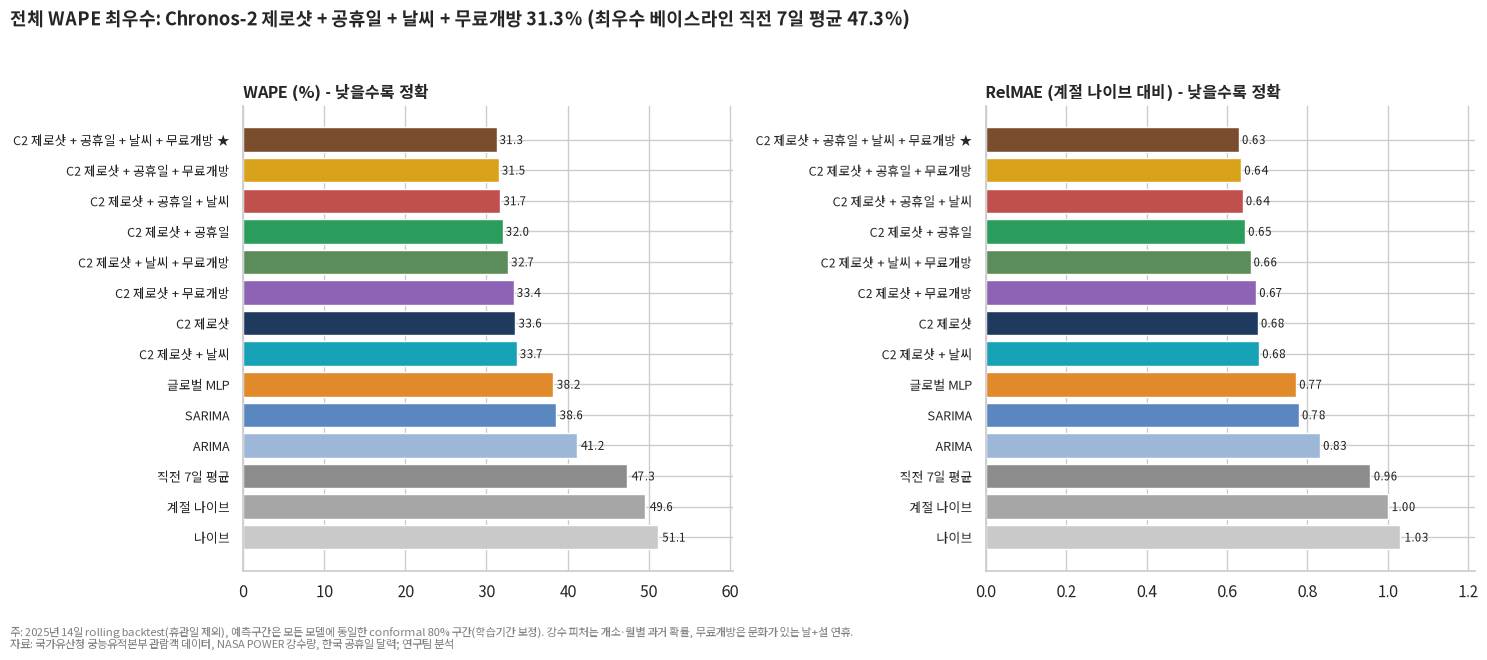

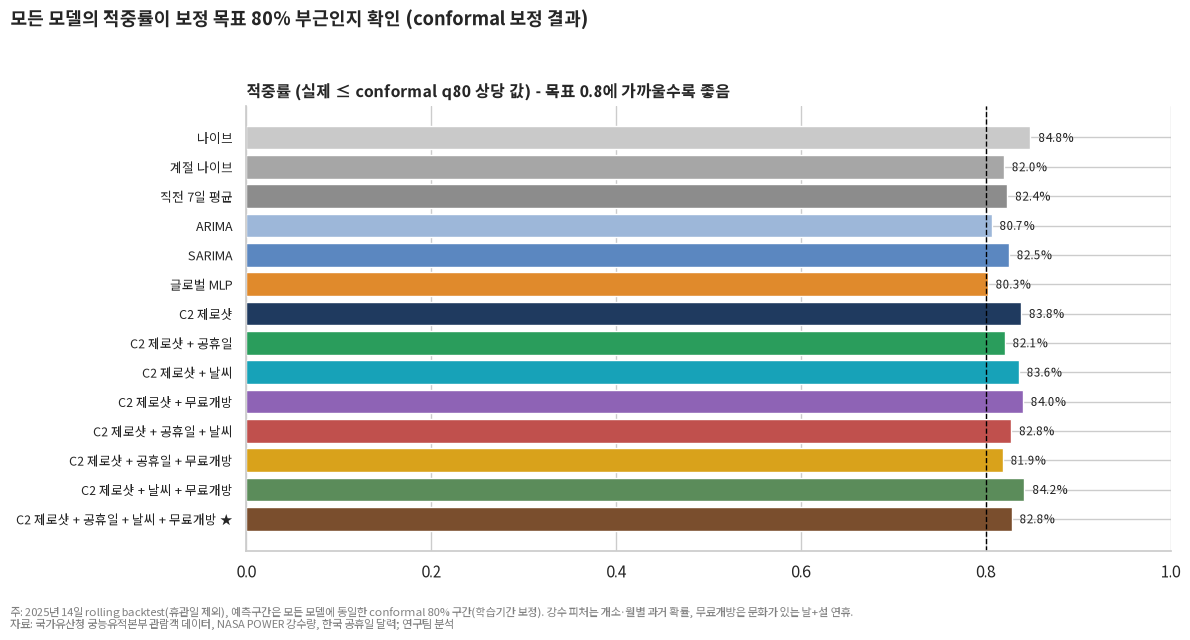

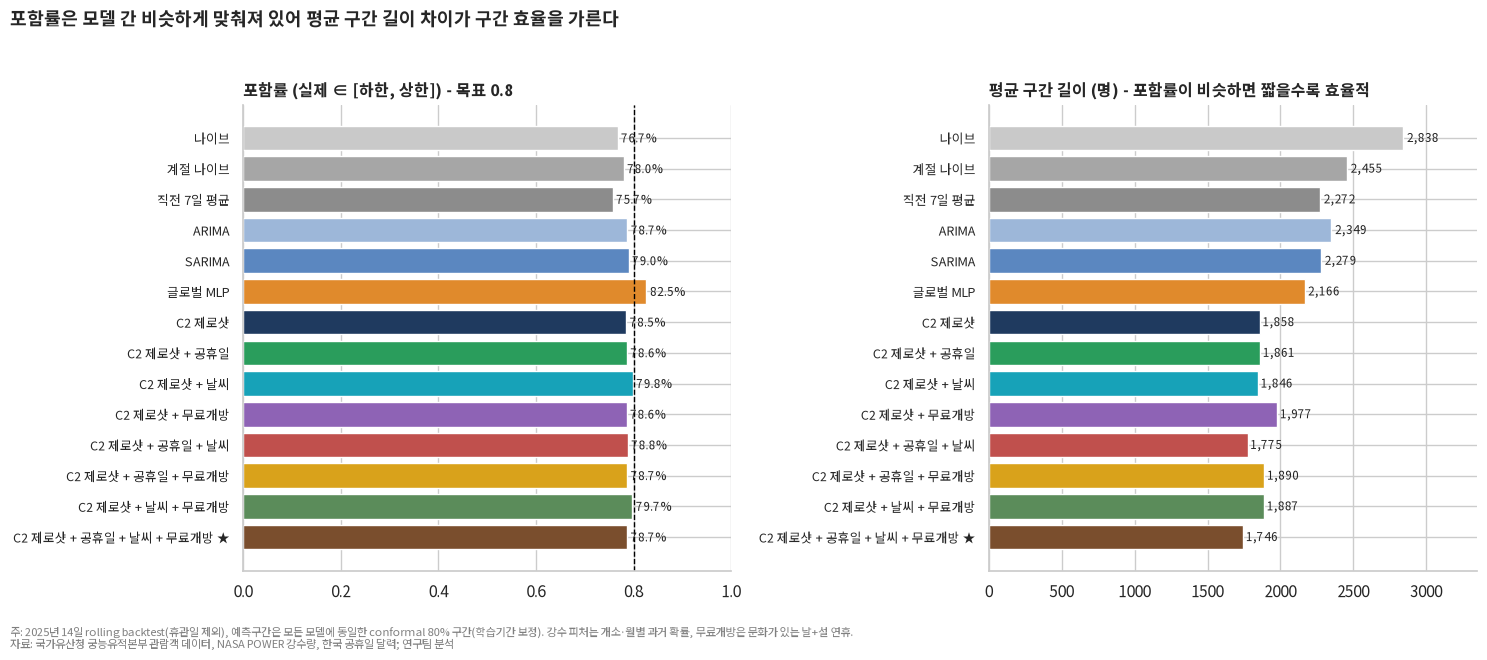

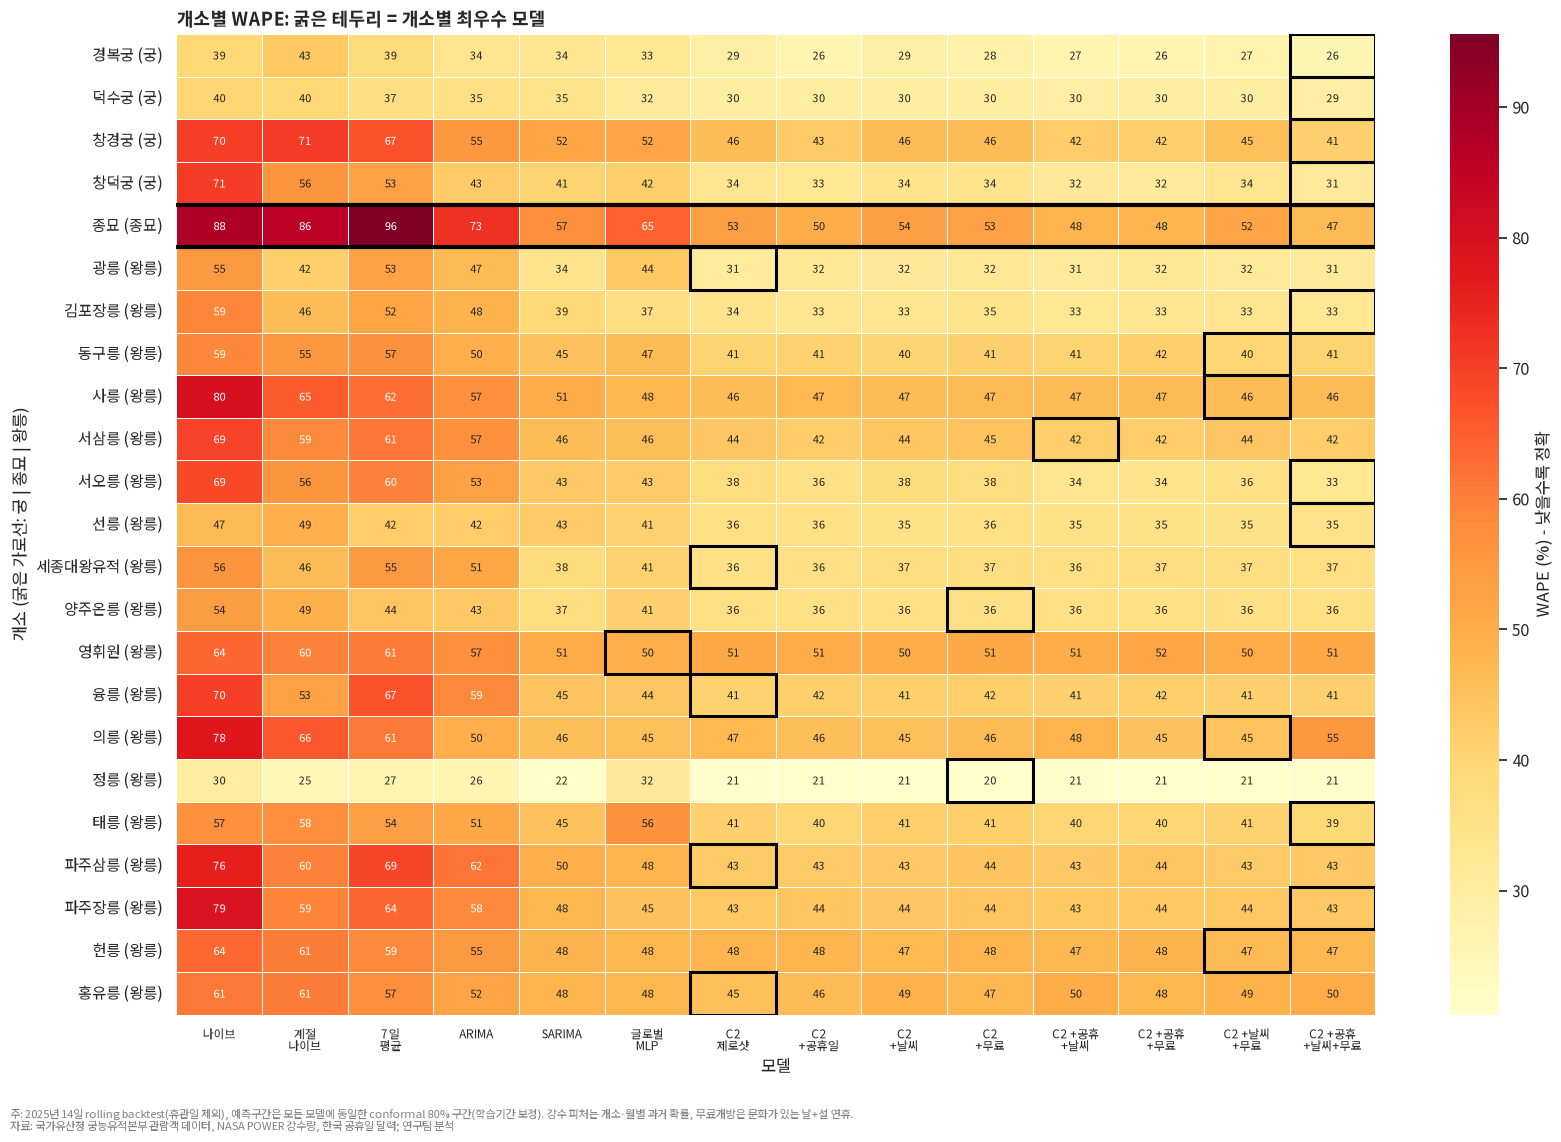

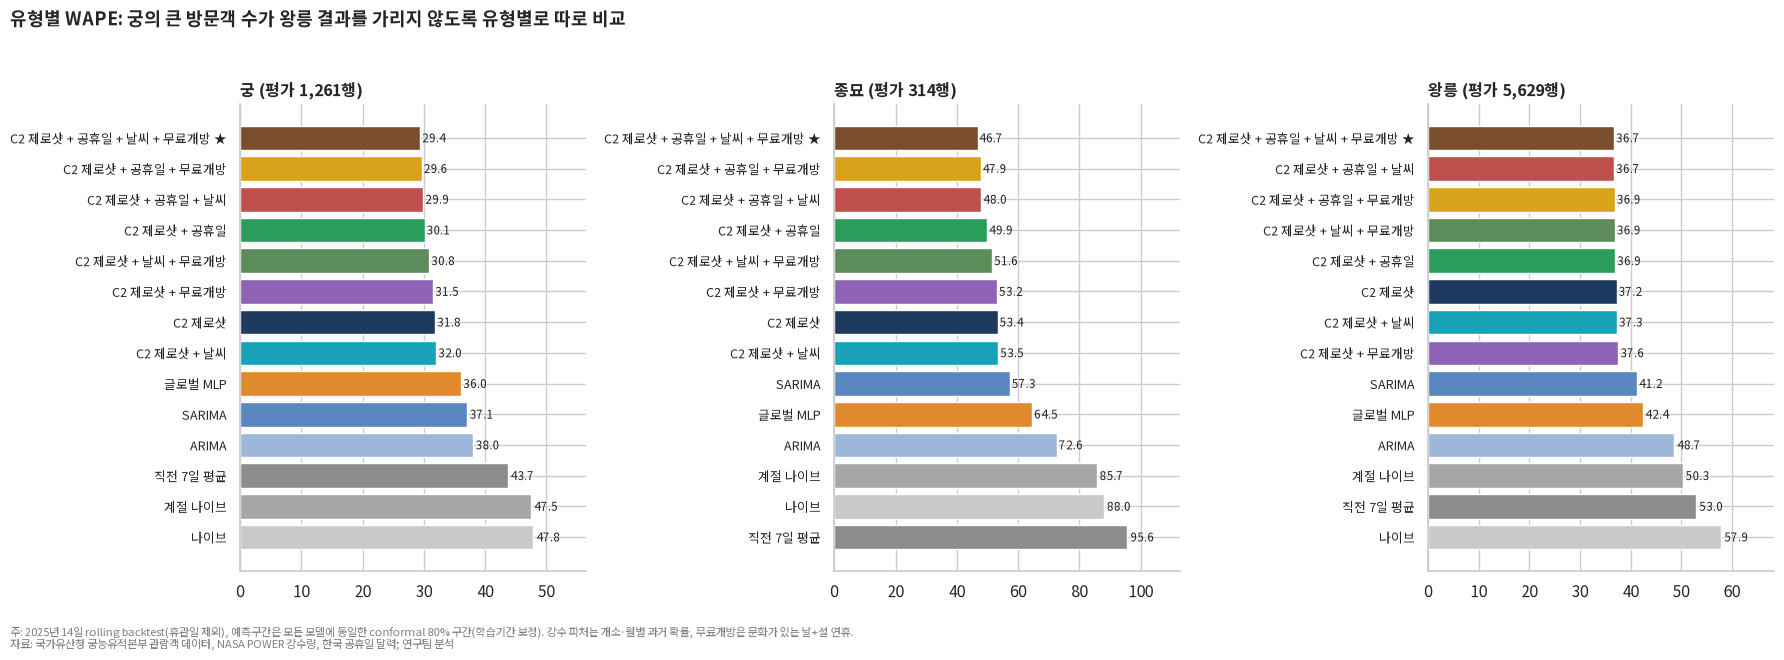

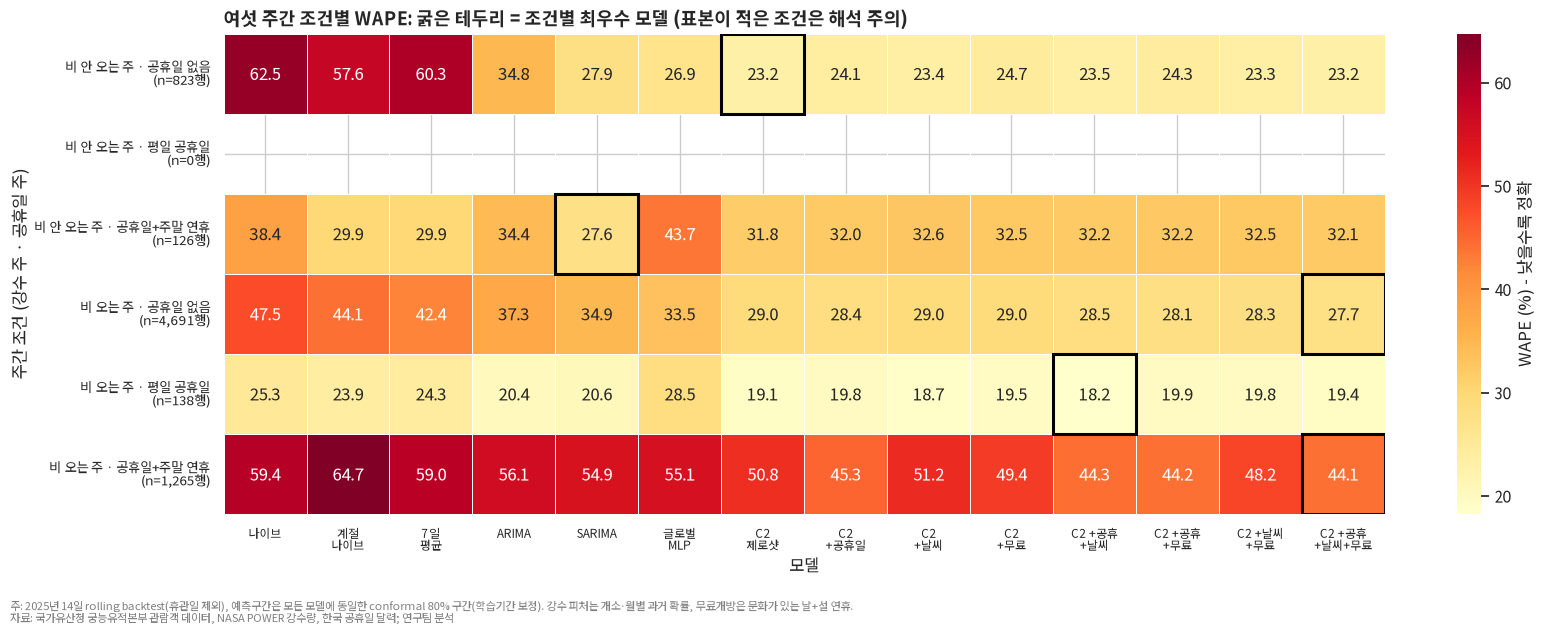

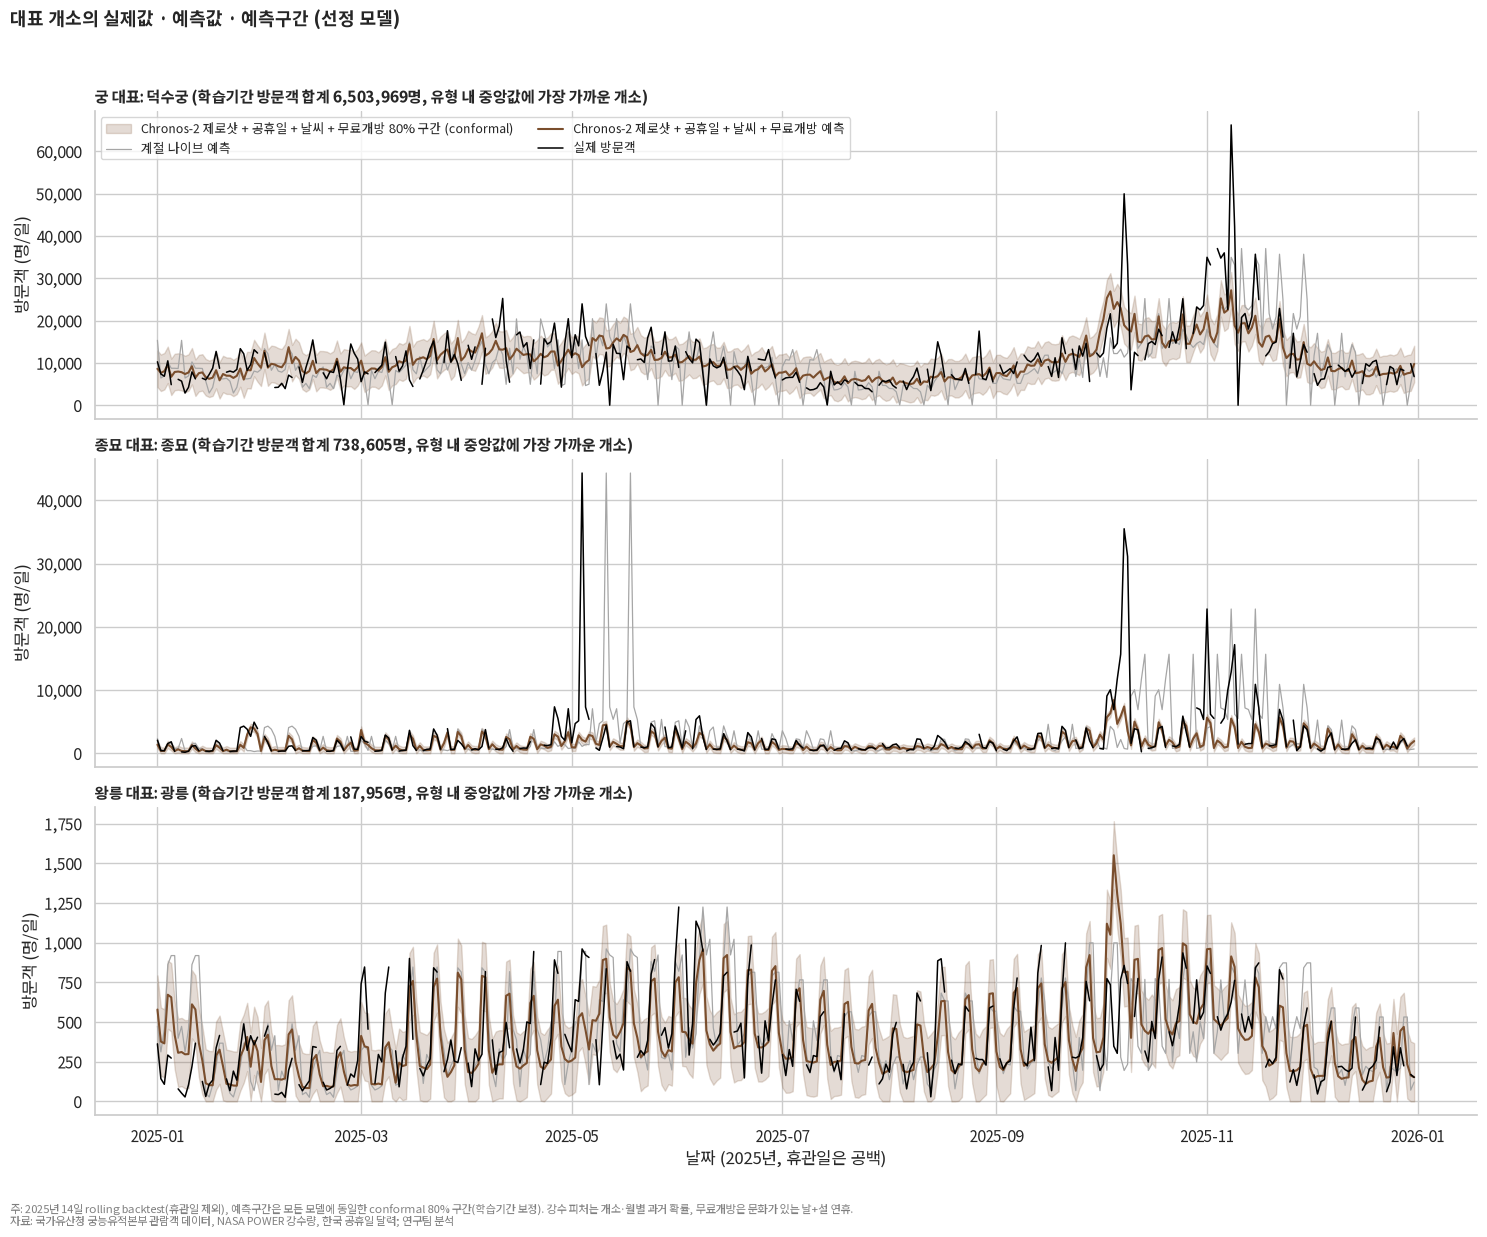

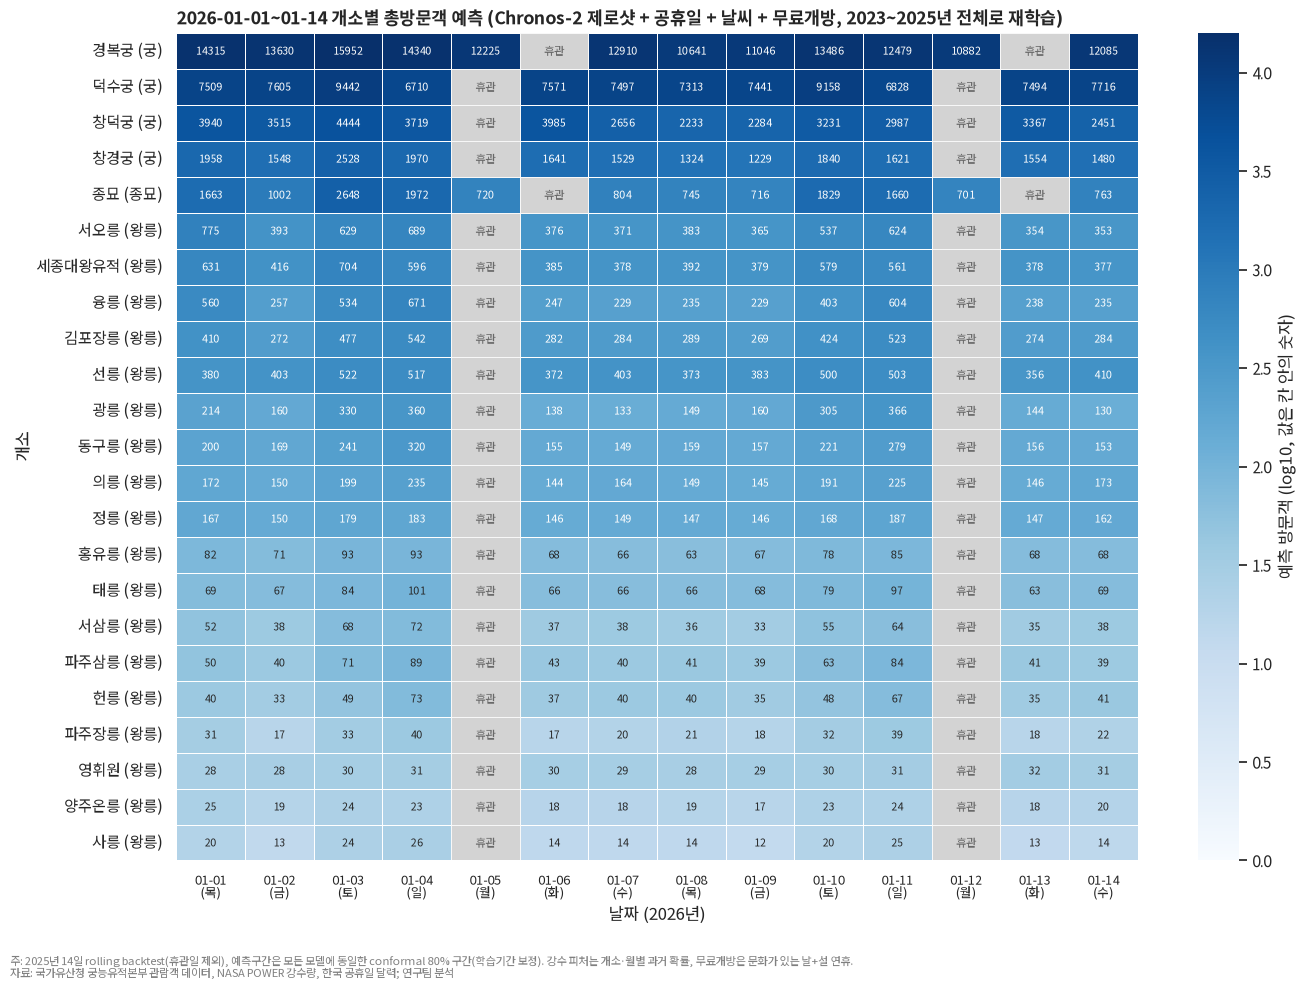

대표 개소(학습기간 방문객 규모 중앙값 기준): {'궁': '덕수궁', '종묘': '종묘', '왕릉': '광릉'} | 글꼴: Noto Sans KR


In [16]:
def setup_korean_font():
    """Noto Sans KR(가변 폰트는 보통·굵은 굵기의 정적 폰트로 변환) → 맑은 고딕 → 나눔고딕 순으로 사용 가능한 한글 폰트를 적용한다."""
    sns.set_theme(style="whitegrid")
    variable = Path("C:/Windows/Fonts/NotoSansKR-VF.ttf")
    statics = {400: CACHE_DIR / "NotoSansKR-Regular-wght400.ttf", 700: CACHE_DIR / "NotoSansKR-Bold-wght700.ttf"}
    if variable.exists():
        try:
            from fontTools.ttLib import TTFont
            from fontTools.varLib import instancer
            for weight, path in statics.items():
                if not path.exists():
                    instancer.instantiateVariableFont(TTFont(str(variable)), {"wght": weight}).save(str(path))
        except Exception as error:
            print("[참고] Noto Sans KR 가변 폰트를 정적 폰트로 변환하지 못했습니다:", type(error).__name__)
    name = None
    for path in [statics[400], Path("C:/Windows/Fonts/NotoSansKR-Regular.ttf"), Path("C:/Windows/Fonts/malgun.ttf")]:
        if path.exists():
            fm.fontManager.addfont(str(path))
            name = fm.FontProperties(fname=str(path)).get_name()
            break
    if statics[700].exists():
        fm.fontManager.addfont(str(statics[700]))
    if name is None:
        installed = sorted({f.name for f in fm.fontManager.ttflist if any(k in f.name.lower() for k in ("noto sans cjk kr", "noto sans kr", "nanum", "malgun"))})
        name = installed[0] if installed else None
    if name is None:
        warnings.warn("한글 폰트를 찾지 못했습니다. 그래프의 한글이 깨질 수 있습니다.")
    else:
        plt.rcParams["font.family"] = name
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
    return name


CHRONOS_COLORS = ["#1F3A5F", "#2a9d5c", "#17a2b8", "#8e63b5", "#c0504d", "#d9a21b", "#5b8c5a", "#7a4e2d"]
MODEL_COLOR = {"baseline_naive": "#c9c9c9", "baseline_seasonal_naive": "#a6a6a6", "baseline_mean7": "#8c8c8c", "arima": "#9db7d9", "sarima": "#5b87c0", "mlp_global": "#e08a2c",
               **dict(zip(CHRONOS_MODELS, CHRONOS_COLORS))}
SOURCE_NOTE = ("주: 2025년 14일 rolling backtest(휴관일 제외), 예측구간은 모든 모델에 동일한 conformal 80% 구간(학습기간 보정). 강수 피처는 개소·월별 과거 확률, 무료개방은 문화가 있는 날+설 연휴.\n"
               "자료: 국가유산청 궁능유적본부 관람객 데이터, NASA POWER 강수량, 한국 공휴일 달력; 연구팀 분석")


def finish(fig, name, note=True):
    if note:
        fig.text(0.01, -0.015, SOURCE_NOTE, fontsize=8, color="#7F7F7F", va="top", ha="left")
    fig.savefig(OUTPUT_DIR / name, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def label_of(model_id):
    return REG[model_id]["label"].replace("Chronos-2 제로샷", "C2 제로샷") + (" ★" if model_id == SELECTED else "")


def bar_panel(ax, table, column, title, fmt, target_line=None, order=None):
    data = table.set_index("model_id").loc[order or table.sort_values(column)["model_id"].tolist()]
    bars = ax.barh([label_of(m) for m in data.index][::-1], data[column].to_numpy()[::-1], color=[MODEL_COLOR[m] for m in data.index][::-1])
    for bar, value in zip(bars, data[column].to_numpy()[::-1]):
        ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2, fmt.format(value), va="center", fontsize=8.5)
    if target_line is not None:
        ax.axvline(target_line, color="black", linestyle="--", linewidth=1)
    ax.set_title(title, loc="left", fontsize=11.5)
    ax.set_xlim(0, np.nanmax(data[column]) * 1.18)
    ax.tick_params(axis="y", labelsize=9)


def plot_wape_relmae(path):
    table = total_overall
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
    bar_panel(axes[0], table, "WAPE", "WAPE (%) - 낮을수록 정확", "{:.1f}")
    bar_panel(axes[1], table, "RelMAE", "RelMAE (계절 나이브 대비) - 낮을수록 정확", "{:.2f}", order=table.sort_values("WAPE")["model_id"].tolist())
    top = RANKING.iloc[0]
    fig.suptitle(f"전체 WAPE 최우수: {REG[SELECTED]['label']} {top['WAPE']:.1f}% (최우수 베이스라인 {best_baseline['model_label']} {best_baseline['WAPE']:.1f}%)", fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    finish(fig, "fig1_wape_relmae.png")


def plot_hit_rate(path):
    fig, ax = plt.subplots(figsize=(12, 6))
    bar_panel(ax, total_overall, "hit_rate", "적중률 (실제 ≤ conformal q80 상당 값) - 목표 0.8에 가까울수록 좋음", "{:.1%}", target_line=COVERAGE_LEVEL, order=MODELS)
    ax.set_xlim(0, 1.0)
    fig.suptitle("모든 모델의 적중률이 보정 목표 80% 부근인지 확인 (conformal 보정 결과)", fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    finish(fig, "fig2_hit_rate.png")


def plot_coverage_width(path):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
    bar_panel(axes[0], total_overall, "coverage", "포함률 (실제 ∈ [하한, 상한]) - 목표 0.8", "{:.1%}", target_line=COVERAGE_LEVEL, order=MODELS)
    axes[0].set_xlim(0, 1.0)
    bar_panel(axes[1], total_overall, "mean_interval_width", "평균 구간 길이 (명) - 포함률이 비슷하면 짧을수록 효율적", "{:,.0f}", order=MODELS)
    fig.suptitle("포함률은 모델 간 비슷하게 맞춰져 있어 평균 구간 길이 차이가 구간 효율을 가른다", fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    finish(fig, "fig3_coverage_width.png")


def plot_site_heatmap(path):
    pivot = site_total.pivot(index="site", columns="model_id", values="WAPE")[MODELS]
    order = site_total.drop_duplicates("site").assign(g=lambda d: d["group"].map({g: i for i, g in enumerate(GROUPS)})).sort_values(["g", "site"])
    pivot = pivot.loc[order["site"]]
    fig, ax = plt.subplots(figsize=(17, 11))
    sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.4, cbar_kws={"label": "WAPE (%) - 낮을수록 정확"}, ax=ax, annot_kws={"fontsize": 8})
    for row, site in enumerate(pivot.index):
        ax.add_patch(plt.Rectangle((int(np.nanargmin(pivot.loc[site].to_numpy())), row), 1, 1, fill=False, edgecolor="black", lw=2.2))
    ax.hlines(np.cumsum(order["group"].value_counts().reindex(GROUPS).fillna(0).to_numpy())[:-1], *ax.get_xlim(), color="black", linewidth=3)
    ax.set_xticklabels([REG[m]["short"] for m in MODELS], rotation=0, fontsize=8.5)
    ax.set_yticklabels([f"{s} ({SITE_GROUP[s]})" for s in pivot.index], rotation=0)
    ax.set_xlabel("모델"); ax.set_ylabel("개소 (굵은 가로선: 궁 | 종묘 | 왕릉)")
    ax.set_title("개소별 WAPE: 굵은 테두리 = 개소별 최우수 모델", fontsize=13, loc="left")
    fig.tight_layout()
    finish(fig, "fig4_site_wape_heatmap.png")


def plot_group_wape(path):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), sharex=False)
    for ax, group in zip(axes, GROUPS):
        part = group_total.loc[group_total["group"] == group]
        if len(part):
            bar_panel(ax, part, "WAPE", f"{group} (평가 {int(part['n_observations'].iloc[0]):,}행)", "{:.1f}")
    fig.suptitle("유형별 WAPE: 궁의 큰 방문객 수가 왕릉 결과를 가리지 않도록 유형별로 따로 비교", fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    finish(fig, "fig5_group_wape.png")


def plot_weekly_conditions(path):
    data = WEEKLY_METRICS.loc[WEEKLY_METRICS["target"] == "total"]
    pivot = data.pivot(index="condition", columns="model_id", values="WAPE").reindex(index=CONDITIONS, columns=MODELS)
    counts = data.drop_duplicates("condition").set_index("condition")["n_observations"].reindex(CONDITIONS)
    fig, ax = plt.subplots(figsize=(17, 6))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.4, cbar_kws={"label": "WAPE (%) - 낮을수록 정확"}, ax=ax)
    for row, condition in enumerate(pivot.index):
        if pivot.loc[condition].notna().any():
            ax.add_patch(plt.Rectangle((int(np.nanargmin(pivot.loc[condition].to_numpy())), row), 1, 1, fill=False, edgecolor="black", lw=2.2))
    ax.set_xticklabels([REG[m]["short"] for m in MODELS], rotation=0, fontsize=8.5)
    ax.set_yticklabels([f"{c}\n(n={int(counts[c]) if pd.notna(counts[c]) else 0:,}행)" for c in pivot.index], rotation=0, fontsize=9.5)
    ax.set_xlabel("모델"); ax.set_ylabel("주간 조건 (강수 주 · 공휴일 주)")
    ax.set_title("여섯 주간 조건별 WAPE: 굵은 테두리 = 조건별 최우수 모델 (표본이 적은 조건은 해석 주의)", fontsize=13, loc="left")
    fig.tight_layout()
    finish(fig, "fig6_weekly_condition_wape.png")


def representative_sites():
    """유형별 중앙값에 가장 가까운 개소 (학습기간 2023~2024 방문객 합계 기준, 테스트 결과나 모델 성능과 무관)."""
    volume = MATRICES["total"].loc[HISTORY_START:TRAIN_END].sum()
    chosen = {}
    for group in GROUPS:
        sites = [s for s in SITES if SITE_GROUP[s] == group]
        median = volume[sites].median()
        chosen[group] = min(sites, key=lambda s: (abs(volume[s] - median), -volume[s]))
    return chosen, volume


def plot_representative(path):
    chosen, volume = representative_sites()
    fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
    for ax, (group, site) in zip(axes, chosen.items()):
        sel = EVAL.loc[(EVAL["site"] == site) & (EVAL["target"] == "total") & (EVAL["model_id"] == SELECTED)].sort_values("date")
        base = EVAL.loc[(EVAL["site"] == site) & (EVAL["target"] == "total") & (EVAL["model_id"] == REFERENCE_MODEL)].sort_values("date")
        ax.fill_between(sel["date"], sel["lower_80"], sel["upper_80"], color=MODEL_COLOR[SELECTED], alpha=0.2, label=f"{REG[SELECTED]['label']} 80% 구간 (conformal)")
        ax.plot(base["date"], base["prediction"], color="#a6a6a6", linewidth=0.9, label="계절 나이브 예측")
        ax.plot(sel["date"], sel["prediction"], color=MODEL_COLOR[SELECTED], linewidth=1.5, label=f"{REG[SELECTED]['label']} 예측")
        ax.plot(sel["date"], sel["actual"], color="black", linewidth=1.1, label="실제 방문객")
        ax.set_ylabel("방문객 (명/일)")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
        ax.set_title(f"{group} 대표: {site} (학습기간 방문객 합계 {volume[site]:,.0f}명, 유형 내 중앙값에 가장 가까운 개소)", fontsize=11, loc="left")
    axes[0].legend(ncol=2, fontsize=9, loc="upper left")
    axes[-1].set_xlabel("날짜 (2025년, 휴관일은 공백)")
    fig.suptitle("대표 개소의 실제값 · 예측값 · 예측구간 (선정 모델)", fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    finish(fig, "fig7_representative_sites.png")
    return chosen


def plot_forecast_2026(path):
    table = FORECAST_2026.copy()
    pivot = table.pivot(index="site", columns="date", values="point_total")
    order = table.drop_duplicates("site").assign(g=lambda d: d["group"].map({g: i for i, g in enumerate(GROUPS)}), v=lambda d: -d.groupby("site")["point_total"].transform("sum")).sort_values(["g", "v"])
    pivot = pivot.loc[order["site"]]
    closed = table.pivot(index="site", columns="date", values="is_regular_closed").loc[order["site"]].astype(bool)
    weekday = table.drop_duplicates("date").set_index("date")["weekday"]
    fig, ax = plt.subplots(figsize=(14, 9.5))
    sns.heatmap(np.log10(pivot.clip(lower=1)), annot=pivot.round(0).astype(int), fmt="d", cmap="Blues", linewidths=0.4, ax=ax, annot_kws={"fontsize": 7.5},
                cbar_kws={"label": "예측 방문객 (log10, 값은 칸 안의 숫자)"})
    for row in range(len(pivot)):
        for col in range(pivot.shape[1]):
            if closed.iloc[row, col]:
                ax.add_patch(plt.Rectangle((col, row), 1, 1, facecolor="lightgray", edgecolor="white", lw=0.5, zorder=3))
                ax.text(col + 0.5, row + 0.5, "휴관", ha="center", va="center", fontsize=8, color="dimgray", zorder=4)
    ax.set_xticklabels([f"{pd.Timestamp(d):%m-%d}\n({weekday[d]})" for d in pivot.columns], rotation=0, fontsize=9)
    ax.set_yticklabels([f"{s} ({SITE_GROUP[s]})" for s in pivot.index], rotation=0)
    ax.set_xlabel("날짜 (2026년)"); ax.set_ylabel("개소")
    ax.set_title(f"2026-01-01~01-14 개소별 총방문객 예측 ({REG[SELECTED]['label']}, 2023~2025년 전체로 재학습)", fontsize=12.5, loc="left")
    fig.tight_layout()
    finish(fig, "fig8_forecast_2026.png")


FONT_NAME = setup_korean_font()
FIGURE_FILES = ["fig1_wape_relmae.png", "fig2_hit_rate.png", "fig3_coverage_width.png", "fig4_site_wape_heatmap.png", "fig5_group_wape.png", "fig6_weekly_condition_wape.png", "fig7_representative_sites.png", "fig8_forecast_2026.png"]
plot_wape_relmae(None); plot_hit_rate(None); plot_coverage_width(None); plot_site_heatmap(None); plot_group_wape(None); plot_weekly_conditions(None)
REPRESENTATIVE = plot_representative(None)
plot_forecast_2026(None)
print("대표 개소(학습기간 방문객 규모 중앙값 기준):", REPRESENTATIVE, "| 글꼴:", FONT_NAME)

## 12. 결과 저장과 요약 보고서 (`comparison_summary.md`)

In [17]:
def md_table(frame, digits=2, index=False):
    frame = frame.reset_index() if index else frame
    head = "| " + " | ".join(str(c) for c in frame.columns) + " |\n|" + "---|" * len(frame.columns) + "\n"
    body = "\n".join("| " + " | ".join(("-" if isinstance(v, (float, np.floating)) and np.isnan(v) else f"{v:,.{digits}f}" if isinstance(v, (float, np.floating)) else (f"{int(v):,}" if isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)) else str(v))) for v in row) + " |" for row in frame.itertuples(index=False))
    return head + body


def similar_models(table, column="WAPE"):
    best = table[column].min()
    return table.loc[table[column] <= best + TIE_TOLERANCE]


def write_summary(path):
    to = total_overall.set_index("model_id")
    top = RANKING.iloc[0]
    family_note = ("베이스라인 3종(나이브·계절 나이브·직전 7일 평균)은 비교안 1의 모델군으로 묶어 보고하며 아래 표에서는 각각 표시합니다.")
    overall_table = RANKING[["rank", "model_label", "WAPE", "RelMAE", "hit_rate", "coverage", "mean_interval_width"]].rename(columns={"rank": "순위", "model_label": "모델", "hit_rate": "적중률", "coverage": "포함률", "mean_interval_width": "평균 구간 길이(명)"})
    near = similar_models(total_overall)
    group_rows = []
    for group in GROUPS:
        part = group_total.loc[group_total["group"] == group]
        best = part.loc[part["WAPE"].idxmin()]
        sel = part.loc[part["model_id"] == SELECTED].iloc[0]
        base = part.loc[part["model_id"].isin(baseline_ids)].sort_values("WAPE").iloc[0]
        group_rows.append([group, int(best["n_observations"]), best["model_label"], best["WAPE"], sel["WAPE"], base["model_label"], base["WAPE"], len(similar_models(part))])
    group_table = pd.DataFrame(group_rows, columns=["유형", "평가 행", "WAPE 최우수 모델", "최우수 WAPE", "선정 모델 WAPE", "최우수 베이스라인", "베이스라인 WAPE", "유사한 수준(0.1%p 이내) 모델 수"])
    royal_sites = site_total.loc[(site_total["group"] == "왕릉")]
    royal_win = int(sum(float(g.loc[g["model_id"] == SELECTED, "WAPE"].iloc[0]) < float(g.loc[g["model_id"].isin(baseline_ids), "WAPE"].min()) for _, g in royal_sites.groupby("site")))
    site_dist = site_best.reindex(MODELS).fillna(0).astype(int)
    week = WEEKLY_METRICS.loc[WEEKLY_METRICS["target"] == "total"]
    week_rows = []
    for condition in CONDITIONS:
        part = week.loc[week["condition"] == condition]
        if part.empty:
            week_rows.append([condition, 0, 0, "-", np.nan, "-", np.nan])
            continue
        best = part.loc[part["WAPE"].idxmin()]
        sel = part.loc[part["model_id"] == SELECTED].iloc[0]
        week_rows.append([condition, int(best["n_site_weeks"]), int(best["n_observations"]), best["model_label"], best["WAPE"], REG[SELECTED]["label"], sel["WAPE"]])
    week_table = pd.DataFrame(week_rows, columns=["주간 조건", "개소·주 수", "관측치 수", "WAPE 최우수 모델", "최우수 WAPE", "선정 모델", "선정 모델 WAPE"])
    empty_conditions = [c for c in CONDITIONS if not (week["condition"] == c).any()]
    empty_note = (f"**관측치가 없는 조건**: {', '.join(empty_conditions)} — 2025년에 해당 조건의 개소·주가 없어(예: 2025년의 평일 공휴일 주는 12월 22~28일 한 주뿐이고 모든 개소에서 비가 온 주) 지표를 계산할 수 없다. 결과에서 삭제하지 않고 관측치 0으로 표시했다.\n\n" if empty_conditions else "")
    interval_table = total_overall[["model_label", "coverage", "mean_interval_width", "hit_rate"]].assign(gap=lambda d: d["coverage"] - COVERAGE_LEVEL).rename(
        columns={"model_label": "모델", "coverage": "포함률", "mean_interval_width": "평균 구간 길이(명)", "hit_rate": "적중률", "gap": "포함률 − 0.8"})
    closest = total_overall.assign(gap=lambda d: (d["coverage"] - COVERAGE_LEVEL).abs()).sort_values("gap").iloc[0]
    acceptable = total_overall.loc[(total_overall["coverage"] - COVERAGE_LEVEL).abs() <= 0.05]
    narrowest = acceptable.sort_values("mean_interval_width").iloc[0] if len(acceptable) else closest
    f26 = FORECAST_2026.loc[~FORECAST_2026["is_regular_closed"]]
    f26_group = f26.groupby("group")["point_total"].sum().reindex(GROUPS)
    f26_site = f26.groupby("site")["point_total"].sum().sort_values(ascending=False).head(5)
    f26_day = f26.groupby("date")["point_total"].sum()
    model_table = pd.DataFrame([[m["item"], m["id"], m["label"]] for m in MODEL_REGISTRY], columns=["비교안", "model_id", "모델"])
    text = f"""# 최종 모델 비교 요약 (Chronos-2 공변량 8종 · 베이스라인 · ARIMA · SARIMA · 글로벌 MLP)

## 1. 분석 목적
2023~2024년을 학습, 2025년을 테스트로 12개 비교안(실행 결과 14개)을 같은 조건에서 비교하고, 선정 모델을 2023~2025년 전체로 다시 학습해 2026-01-01~14 개소별 방문객을 예측한다.

## 2. 데이터와 기간
- 전처리 방문객 파일(`heritage_visitors_daily_preprocessed_2023_2025.csv`), 개소 {len(SITES)}곳(궁 4·종묘 1·왕릉 18 구분 기존 프로젝트와 동일{' — 디버그 실행은 일부 개소' if FAST_DEBUG else ''}), 휴관일(목표 NaN)은 학습·평가 제외.
- 기존 구조대로 `domestic`·`foreign_total`을 따로 예측해 `total`로 합산하고 total을 1차 평가 대상으로 한다.
- 학습 {HISTORY_START.date()}~{TRAIN_END.date()}, 테스트 {TEST_START.date()}~{TEST_END.date()}, 최종 학습 {HISTORY_START.date()}~{FINAL_TRAIN_END.date()}, 최종 예측 {FORECAST_START.date()}~{FORECAST_END.date()}.

## 3. 14일 rolling backtest 방법
2025년을 14일 단위 {len(TEST_WINDOWS)}개 구간으로 나누고 구간마다 원점까지의 이력만으로 다음 14일을 예측한다 (베이스라인은 구간 안에서 앞서 만든 예측값만 재귀 사용). 모든 모델이 같은 원점·날짜·개소·실제값을 쓴다. 지표는 WAPE(1순위)·RelMAE(보조)·적중률·포함률·평균 구간 길이만 사용하고 종합점수는 만들지 않았다.
예측구간은 모든 모델에 학습기간(2024-07-03~2024-12-31)의 rolling 오차로 만든 개소별 split conformal 80% 구간을 적용했다. 적중률은 같은 방식의 q80 상당 한계(실제 ≤ q80)를 쓴다.

## 4. 비교 모델
{family_note}

{md_table(model_table)}

## 5. 강수확률 생성 방법
일 강수량에서 `rain = precip_mm ≥ 1`, `heavy = precip_mm ≥ 10`, `after_heavy = 전날 heavy이고 당일 precip_mm < 1`(같은 개소의 전날 기준)을 만들고, 같은 개소·같은 월의 평균을 `rain_prob`·`heavy_prob`·`after_heavy_prob`(하나의 강수 피처 블록)로 쓴다. 2025 테스트용은 2023~2024 날씨만, 2026 예측용은 2023~2025 날씨만으로 계산했고 학습 행과 예측 행에 같은 표를 사용했다. 실제 일별 강수는 모델 입력이 아니라 주간 조건 분류에만 쓴다. 기온은 사용하지 않았다.

## 6. 무료개방 규칙
`free_open = 1`: ① 문화가 있는 날(해당 월의 모든 수요일 중 가장 늦은 수요일) ② 설 연휴(기존 달력에서 설 연휴로 분류된 공휴일: 설날 전날·당일·다음날·대체휴일). 2025·2026에 같은 규칙을 적용하고, 정기 휴관 요일(공휴일 제외)은 0으로 처리했다. 적용 개소는 전체 개소이며 근거(학습기간 무료 관람 비중)는 노트북 섹션 5에 출력했다. 행사성·비정기 무료개방은 포함하지 않았다.

## 7. 전체 모델 성능 (total, 전체 개소 통합, 순위 규칙: WAPE → RelMAE → 적중률 → 포함률·구간 길이)
{md_table(overall_table, 3)}

- WAPE 1위: **{top['model_label']}** ({top['WAPE']:.2f}%). WAPE가 1위와 0.1%p 이내인 *유사한 수준* 모델: {', '.join(near['model_label'])}. 최우수 베이스라인은 {best_baseline['model_label']} ({best_baseline['WAPE']:.2f}%)이다.

## 8. 개소별·유형별 결과
{md_table(group_table, 2)}

- 개소별 WAPE 최우수 모델 분포(23곳 중): {', '.join(f'{REG[m]["label"]} {n}곳' for m, n in site_dist.items() if n > 0)}.
- **왕릉 별도 설명**: 왕릉은 개소 수가 많지만 방문객이 적어 궁의 큰 방문객 수에 가려지기 쉽다. 왕릉 {len(royal_sites['site'].unique())}곳 중 선정 모델이 최우수 베이스라인보다 WAPE가 낮은 개소는 {royal_win}곳이며, 왕릉 유형의 WAPE 최우수는 {group_total.loc[(group_total['group'] == '왕릉')].sort_values('WAPE').iloc[0]['model_label']}이다. 전체 결과만으로 모델을 정하지 않고 위 표의 유형별 결과와 개소별 분포를 함께 확인했다.

## 9. 여섯 개 주간 조건별 결과 (total, 평가 개소·주 기준)
{md_table(week_table, 2)}

{empty_note}관측치가 적은 조건(특히 공휴일+주말 연휴 주)은 해석에 주의하고 단독 근거로 쓰지 않는다. 전체 조건별·개소별 표는 `weekly_condition_metrics.csv`, `site_weekly_condition_metrics.csv`에 있다.

## 10. 예측구간의 포함률과 길이
{md_table(interval_table, 3)}

- 모든 모델에 같은 conformal 80% 구간을 쓰므로 포함률은 대체로 목표 0.8 부근이며(목표에 가장 가까운 모델: {closest['model_label']} {closest['coverage']:.1%}), 포함률이 비슷하면 평균 구간 길이가 짧은 모델이 더 효율적이다. 포함률이 0.8±0.05 안에서 구간이 가장 짧은 모델은 **{narrowest['model_label']}** (평균 {narrowest['mean_interval_width']:,.0f}명)이다. 포함률이 높아도 구간이 지나치게 넓으면 우수한 구간 예측이라고 단정하지 않는다.

## 11. 2026년 14일 예측 결과 (`forecast_2026_14days.csv`)
선정 모델 **{REG[SELECTED]['label']}**을 2023~2025년 전체로 다시 학습해 예측했다. 정기 휴관일을 제외한 개장일 총방문객 점 예측 합계는 {f26['point_total'].sum():,.0f}명이며 유형별로 궁 {f26_group['궁']:,.0f}명, 종묘 {f26_group['종묘']:,.0f}명, 왕릉 {f26_group['왕릉']:,.0f}명이다. 개소별 상위 5곳: {', '.join(f'{s} {v:,.0f}명' for s, v in f26_site.items())}. 일별 합계는 {f26_day.min():,.0f}~{f26_day.max():,.0f}명(최대 {f26_day.idxmax()})이다.

## 12. 최종 모델 선택
- 순위 규칙(WAPE → RelMAE → 적중률 → 포함률·구간 길이 균형)에 따라 **{REG[SELECTED]['label']}**(`{SELECTED}`)을 최종 모델로 선정했다 (WAPE {top['WAPE']:.2f}%, RelMAE {top['RelMAE']:.3f}, 적중률 {top['hit_rate']:.1%}, 포함률 {top['coverage']:.1%}, 평균 구간 길이 {top['mean_interval_width']:,.0f}명).
- 유형별 확인: 선정 모델 WAPE − 최우수 베이스라인 WAPE = {', '.join(f'{g} {v:+.2f}%p' for g, v in group_vs_baseline.items())}. 음수이면 해당 유형에서도 베이스라인보다 낮다. WAPE 차이가 0.1%p 이내인 모델은 *유사한 수준*이므로 모델 간 작은 차이를 확실한 개선이라고 보지 않는다.

## 13. 한계
- 강수확률은 실제 기상예보가 아니라 해당 개소·월의 **과거 월별 발생확률**이다.
- 2025년 실제 강수는 모델 입력이 아니라 **조건별 평가(주간 강수 구분)에만** 사용했다.
- `after_heavy_prob`는 특정 날짜의 전날 큰비 발생을 예측하는 변수가 아니라 과거 발생빈도다.
- 무료개방은 사전에 정의한 규칙(문화가 있는 날, 설 연휴)만 반영했다.
- 행사성 또는 비정기 무료개방은 포함하지 않았다.
- 2026년 실제 운영 시에는 확보한 기상예보와 확정된 무료개방 일정으로 공변량을 갱신할 필요가 있다.
- 예측구간은 모든 모델에 같은 split conformal 방식(학습기간 후반 6개월의 개소별 오차)으로 만든 것이며, ARIMA·SARIMA 차수는 보정 구간을 포함한 학습기간 전체로 한 번 선택했다(보정 구간 약간의 낙관 가능). 개소·조건 단위 결과는 2025년 한 해 기준이라 일반화에 주의해야 한다.
"""
    path.write_text(text, encoding="utf-8")


def save_outputs():
    """보고서용 CSV·요약 md는 outputs에, 상세 일별 평가 행은 cache에 저장한다 (index=False, utf-8-sig)."""
    files = {"overall_metrics.csv": OVERALL, "site_metrics.csv": SITE_METRICS, "type_metrics.csv": TYPE_METRICS, "weekly_condition_metrics.csv": WEEKLY_METRICS,
             "site_weekly_condition_metrics.csv": SITE_WEEKLY_METRICS, "model_ranking.csv": RANKING, "forecast_2026_14days.csv": FORECAST_2026}
    for name, table in files.items():
        table.to_csv(OUTPUT_DIR / name, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
    fit_log = pd.concat(FIT_LOGS, ignore_index=True) if FIT_LOGS else pd.DataFrame(columns=["model_id", "phase", "fold", "site", "target", "status", "fallback_to", "reason", "converged"])
    fit_log.to_csv(OUTPUT_DIR / "model_fit_log.csv", index=False, encoding="utf-8-sig")
    EVAL.drop(columns=["q10", "q50", "q80", "q90"]).to_csv(CACHE_DIR / "eval_rows_detail.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
    write_summary(OUTPUT_DIR / "comparison_summary.md")
    return [OUTPUT_DIR / n for n in list(files) + ["model_fit_log.csv", "comparison_summary.md"]] + [OUTPUT_DIR / n for n in FIGURE_FILES]


SAVED = save_outputs()
for path in SAVED:
    assert path.stat().st_size > 0, f"빈 파일: {path}"
print(f"저장 완료: {len(SAVED)}개 파일 → {OUTPUT_DIR.as_posix()}")

저장 완료: 17개 파일 → outputs/final_model_comparison


## 13. 필수 검증
각 항목이 통과하면 `PASS`를 출력하고 실패하면 `assert`로 실행을 중단합니다.

In [18]:
def tamper_future(frames, origin):
    return {site: frame.assign(target=np.where(frame.index > origin, 1e7, frame["target"])) for site, frame in frames.items()}


def leakage_checks():
    window = TEST_WINDOWS.iloc[[0]]
    origin = window["origin"].iloc[0]
    results = {}
    for model_id in ("chronos_zero", "chronos_holiday_weather_free"):
        for target in TARGETS:
            frames = build_target_frames(target, "test")
            a = run_chronos(get_pipeline(), REG[model_id]["covariates"], window, frames)
            b = run_chronos(get_pipeline(), REG[model_id]["covariates"], window, tamper_future(frames, origin))
            results[f"{model_id}|{target}"] = bool(np.allclose(a[QUANTILE_COLUMNS].to_numpy(), b[QUANTILE_COLUMNS].to_numpy(), rtol=1e-5))
    saved = {t: m.copy() for t, m in MATRICES.items()}
    try:
        for t in MATRICES:
            changed = saved[t].copy()
            changed.loc[changed.index > origin, :] = 1e7           # origin 이후 실제값(및 결측)을 극단값으로 변조
            MATRICES[t] = changed
        tampered = forecast_baselines(window)
    finally:
        MATRICES.update(saved)
    original = BASELINE_PRED.loc[BASELINE_PRED["fold"] == window["fold"].iloc[0]].sort_values(["model_id", "target", "site", "horizon"])
    results["baselines"] = bool(np.allclose(original["prediction"].to_numpy(), tampered.sort_values(["model_id", "target", "site", "horizon"])["prediction"].to_numpy()))
    return results


def run_validations():
    leak = leakage_checks()
    info = read_info()
    key_total = EVAL.loc[EVAL["target"] == "total"]
    row_keys = {m: set(zip(g["date"], g["site"])) for m, g in key_total.groupby("model_id")}
    # --- 강수 피처 검증
    tampered_daily = {site: frame.assign(**{c: np.where(frame.index >= TEST_START, 1, frame[c]) for c in ("rain", "heavy", "after_heavy")}) for site, frame in WEATHER_DAILY.items()}
    prob_tampered, prob_test = monthly_probabilities(tampered_daily, TRAIN_END), {s: COVARIATES["test"][s][WEATHER_FEATURES] for s in SITES}
    prob_independent = {}
    raw_weather = WEATHER.set_index(["site", "date"])["precip_mm"]
    for site in SITES[:2]:
        precip = raw_weather.loc[site].sort_index()
        prev = precip.shift(1)
        daily_ref = pd.DataFrame({"rain": (precip >= RAIN_MM).astype(int), "heavy": (precip >= HEAVY_MM).astype(int), "after_heavy": ((prev >= HEAVY_MM) & (precip < RAIN_MM)).astype(int)})
        prob_independent[site] = (daily_ref.loc[HISTORY_START:FINAL_TRAIN_END].groupby(daily_ref.loc[HISTORY_START:FINAL_TRAIN_END].index.month).mean(),
                                  daily_ref.loc[HISTORY_START:TRAIN_END].groupby(daily_ref.loc[HISTORY_START:TRAIN_END].index.month).mean(), daily_ref)
    after_ok = all((prob_independent[s][2].loc[HISTORY_START:TEST_END, "after_heavy"].to_numpy() == WEATHER_DAILY[s]["after_heavy"].loc[HISTORY_START:TEST_END].to_numpy()).all() for s in SITES[:2])
    final_ok = all(np.allclose(COVARIATES["final"][s].loc["2026-01-05", WEATHER_FEATURES].to_numpy(dtype=float), prob_independent[s][0].loc[1, ["rain", "heavy", "after_heavy"]].to_numpy()) for s in SITES[:2])
    test_ok = all(np.allclose(COVARIATES["test"][s].loc["2025-03-10", WEATHER_FEATURES].to_numpy(dtype=float), prob_independent[s][1].loc[3, ["rain", "heavy", "after_heavy"]].to_numpy()) for s in SITES[:2])
    # --- 무료개방 검증
    months = [p for p in pd.period_range(HISTORY_START, FORECAST_END, freq="M")]
    lw = last_wednesdays(HISTORY_START, FORECAST_END)
    free_ok = bool(len(lw) == len(months) and (lw.dayofweek == FREE_OPEN_WEEKDAY).all() and all((d + pd.Timedelta(days=7)).month != d.month for d in lw))
    site0 = SITES[0]
    seollal_flag_ok = bool((FREE_OPEN[site0].loc[SEOLLAL_DAYS[SEOLLAL_DAYS].index] == 1).all() and SEOLLAL_DAYS.loc["2025-01-27"] and SEOLLAL_DAYS.loc["2024-02-12"])
    free_in_window = FREE_OPEN[site0].loc[lw[lw <= FORECAST_END]].sum() == len(lw[lw <= FORECAST_END])
    # --- 주간 조건 검증
    week_assign = WEEK_CONDITIONS.drop_duplicates(["site", "week_start"]).groupby(["site", "week_start"]).size()
    nan_dates = EVAL.loc[EVAL["condition"].isna(), "date"]
    allowed_nan = nan_dates.between("2025-01-01", "2025-01-05") | nan_dates.between("2025-12-29", "2025-12-31") if len(nan_dates) else pd.Series([True])
    if FAST_DEBUG:
        week_ok = bool((week_assign == 1).all())
    else:
        week_ok = bool((week_assign == 1).all() and len(HOLIDAY_WEEKS) == 51 and allowed_nan.all() and set(WEEK_CONDITIONS["condition"].unique()) <= set(CONDITIONS))
    # --- 구간 검증
    cal_cov = CAL_TEST.merge(PARAMS_TEST, on=["model_id", "target", "site"]).assign(inside=lambda d: d["residual"].abs() <= d["q_abs"]).groupby(["model_id", "target"])["inside"].mean()
    conformal_parts = dict(lower_nonneg=bool((EVAL["lower_80"] >= 0).all()), upper_ge_lower=bool((EVAL["upper_80"] >= EVAL["lower_80"]).all()), q80_nonneg=bool((EVAL["q80_equiv"] >= 0).all()),
                           calibration_coverage_ok=bool((cal_cov >= COVERAGE_LEVEL - 1e-9).all()), no_nan=bool(EVAL[["lower_80", "upper_80", "q80_equiv"]].notna().all().all()))
    print("conformal 세부 점검:", conformal_parts, "| 보정 구간 포함률 최솟값", round(float(cal_cov.min()), 4))
    # --- 합산·베이스라인 검증
    piv = EVAL.pivot_table(index=["model_id", "date", "site"], columns="target", values="prediction")
    reference_ok = True
    if PATHS["reference_baselines"].exists():
        ref = pd.read_csv(PATHS["reference_baselines"], encoding="utf-8-sig", parse_dates=["date"])
        for model_id, base in BASELINE_BASES.items():
            merged = EVAL.loc[(EVAL["model_id"] == model_id) & (EVAL["target"] == "total")].merge(ref.loc[ref["model"] == base, ["date", "site", "prediction"]].rename(columns={"prediction": "stored"}), on=["date", "site"])
            reference_ok &= bool(len(merged) > 0 and np.allclose(merged["prediction"], merged["stored"], atol=1e-6))
    earlier_ok = True
    for model_id, key in (("chronos_zero", "earlier_chronos_zero"), ("chronos_holiday", "earlier_chronos_holiday")):
        if PATHS[key].exists():
            old = pd.read_csv(PATHS[key], encoding="utf-8-sig", parse_dates=["date"])
            old = old.assign(q50=np.sort(np.clip(old[QUANTILE_COLUMNS].to_numpy(dtype=float), 0, None), axis=1)[:, 1])        # 기존 노트북과 같은 처리(0 미만 절단 + 행 안 정렬) 후 중앙값 비교
            merged = EVAL.loc[(EVAL["model_id"] == model_id) & EVAL["target"].isin(TARGETS)].merge(old[["date", "site", "target", "q50"]].rename(columns={"q50": "earlier"}), on=["date", "site", "target"])
            earlier_ok &= bool(len(merged) > 0 and np.allclose(merged["prediction"], merged["earlier"], rtol=1e-3, atol=1e-3))
    raw_wape = {m: float((g["actual"] - g["prediction"]).abs().sum() / g["actual"].abs().sum() * 100) for m, g in EVAL.loc[(EVAL["target"] == "total") & ~EVAL["is_closed"]].groupby("model_id")}
    final_weather_ok = bool(np.allclose(COVARIATES["final"][SITES[0]].loc[FORECAST_START, WEATHER_FEATURES].to_numpy(dtype=float), prob_independent[SITES[0]][0].loc[1, ["rain", "heavy", "after_heavy"]].to_numpy()))
    mlp_training = info["mlp_global"]["training"]
    checks = {
        "미래 실제 방문객 미입력 (Chronos-2 두 모델·베이스라인: origin 이후 값을 변조해도 예측 불변)": all(leak.values()),
        "모든 모델이 같은 날짜·개소 평가 행 사용 (total 기준)": all(keys == row_keys[MODELS[0]] for keys in row_keys.values()) and len(row_keys) == len(MODELS),
        "공변량 목록이 모델 정의와 정확히 일치 (기온·불필요한 열 없음)": all(set(sum([info[m]["covariate_audit"][t]["context_columns"] + info[m]["covariate_audit"][t]["future_columns"] for t in TARGETS], [])) == set(REG[m]["covariates"]) for m in CHRONOS_MODELS),
        "글로벌 MLP는 개소·유형·요일·월 피처만 사용 (공휴일·강수·무료개방 없음)": list(mlp_features(VISITORS.head(3)).columns) == ["site", "group", "weekday", "month"] and all(v["train_end"] <= str(FINAL_TRAIN_END.date()) for v in mlp_training.values()),
        "2025 테스트용 강수확률은 2023~2024 날씨만 사용 (2025 날씨를 바꿔도 불변, 독립 재계산과 일치)": bool(all(np.allclose(prob_tampered[s].to_numpy(), prob_test[s].to_numpy()) for s in SITES) and test_ok),
        "2026 예측용 강수확률은 2023~2025 날씨 월평균과 일치 (2025 날씨 복사 아님)": bool(final_ok and final_weather_ok),
        "after_heavy는 같은 개소의 전날 heavy 기준 (독립 재계산과 일치)": after_ok,
        "무료개방: 매월 마지막 수요일(월 전체 수요일 중 최댓값)과 설 연휴(2025-01-27 임시공휴일 포함)가 모두 1, 같은 규칙을 2025·2026에 적용": bool(free_ok and seollal_flag_ok and free_in_window),
        "주간 조건: 각 개소·주가 정확히 하나의 조건에 배정, 불완전한 주 제외(완전한 주 51개)": week_ok,
        "보정 오차는 학습기간(≤2024-12-31)만 사용, 2025 테스트 실제값 미사용": bool(CAL_TEST["date"].max() <= TRAIN_END and (PARAMS_TEST["n_cal"] >= MIN_CAL_ROWS).all()),
        "conformal 구간이 유효 (하한 ≥ 0, 상한 ≥ 하한, q80 ≥ 0, 보정 구간 포함률이 목표 0.8 이상)": all(conformal_parts.values()),
        "total 예측 = domestic + foreign_total 예측 (모든 모델)": bool(np.allclose(piv["total"], piv["domestic"] + piv["foreign_total"])),
        "베이스라인 3종(total)이 기존 프로젝트의 저장 결과(Naive·Seasonal Naive·7-day Mean)와 일치": bool(reference_ok),
        "Chronos-2 제로샷·공휴일 모델이 같은 설정의 기존 Chronos-2 비교 노트북 예측과 일치": bool(earlier_ok),
        "휴관일(실제값 NaN)이 평가에서 제외되고 전체 WAPE가 원자료에서 직접 다시 계산한 값과 일치": bool(all(abs(raw_wape[m] - float(total_overall.loc[total_overall["model_id"] == m, "WAPE"].iloc[0])) < 1e-9 for m in MODELS) and EVAL["is_closed"].sum() > 0),
        "결과 표의 지표 열이 WAPE·RelMAE·적중률·포함률·평균 구간 길이 다섯 가지뿐 (RMSE·MAPE·R² 등 없음)": bool(set(OVERALL.columns) - {"model_id", "model_label", "model_family", "comparison_item", "target", "n_observations", "low_n_note"} == set(METRICS)),
        "14개 실행 결과 = 12개 비교안 (베이스라인 3종은 비교안 1), 제외 모델(chronos_wx 등) 없음": bool(len(MODELS) == 14 and len({REG[m]["item"] for m in MODELS}) == 12 and not any("wx" in m or "cal_rain" in m for m in MODELS)),
        "2026 예측: 2026-01-01~14, 모든 개소, 학습기간 2023~2025, 정기 휴관일 0, 선정 모델 단일": bool(
            FORECAST_2026["date"].nunique() == 14 and FORECAST_2026["site"].nunique() == len(SITES) and (FORECAST_2026["training_period"] == "2023-01-01~2025-12-31").all()
            and (FORECAST_2026.loc[FORECAST_2026["is_regular_closed"], "point_total"] == 0).all() and FORECAST_2026["model_id"].nunique() == 1 and (FORECAST_2026["point_total"] >= 0).all()),
    }
    for name, passed in checks.items():
        assert passed, f"검증 실패: {name}"
        print("PASS ", name)
    print(f"\n모든 검증 통과 ({len(checks)}개). 누수 점검:", leak)
    return checks


CHECKS = run_validations()

conformal 세부 점검: {'lower_nonneg': True, 'upper_ge_lower': True, 'q80_nonneg': True, 'calibration_coverage_ok': True, 'no_nan': True} | 보정 구간 포함률 최솟값 0.8083


PASS  미래 실제 방문객 미입력 (Chronos-2 두 모델·베이스라인: origin 이후 값을 변조해도 예측 불변)
PASS  모든 모델이 같은 날짜·개소 평가 행 사용 (total 기준)
PASS  공변량 목록이 모델 정의와 정확히 일치 (기온·불필요한 열 없음)
PASS  글로벌 MLP는 개소·유형·요일·월 피처만 사용 (공휴일·강수·무료개방 없음)
PASS  2025 테스트용 강수확률은 2023~2024 날씨만 사용 (2025 날씨를 바꿔도 불변, 독립 재계산과 일치)
PASS  2026 예측용 강수확률은 2023~2025 날씨 월평균과 일치 (2025 날씨 복사 아님)
PASS  after_heavy는 같은 개소의 전날 heavy 기준 (독립 재계산과 일치)
PASS  무료개방: 매월 마지막 수요일(월 전체 수요일 중 최댓값)과 설 연휴(2025-01-27 임시공휴일 포함)가 모두 1, 같은 규칙을 2025·2026에 적용
PASS  주간 조건: 각 개소·주가 정확히 하나의 조건에 배정, 불완전한 주 제외(완전한 주 51개)
PASS  보정 오차는 학습기간(≤2024-12-31)만 사용, 2025 테스트 실제값 미사용
PASS  conformal 구간이 유효 (하한 ≥ 0, 상한 ≥ 하한, q80 ≥ 0, 보정 구간 포함률이 목표 0.8 이상)
PASS  total 예측 = domestic + foreign_total 예측 (모든 모델)
PASS  베이스라인 3종(total)이 기존 프로젝트의 저장 결과(Naive·Seasonal Naive·7-day Mean)와 일치
PASS  Chronos-2 제로샷·공휴일 모델이 같은 설정의 기존 Chronos-2 비교 노트북 예측과 일치
PASS  휴관일(실제값 NaN)이 평가에서 제외되고 전체 WAPE가 원자료에서 직접 다시 계산한 값과 일치
PASS  결과 표의 지표 열이 WAPE·RelMAE·적중률·포함률·평균 구간 길이 다섯 가지뿐 (RMSE·MAPE·R² 등 없음)
PASS  14개 실행 결과 = 

## 14. 최종 결과 요약

In [19]:
print("생성된 파일:")
for path in SAVED:
    print(f"  {path.stat().st_size:>10,} bytes  {path.as_posix()}")
print("\n[최종 모델 순위 (total, 전체 개소 통합)]")
display(RANKING[["rank", "model_label", "WAPE", "RelMAE", "hit_rate", "coverage", "mean_interval_width", "similar_to_best", "n_sites_best_wape", "groups_best_wape"]].round(3))
print(f"\n선정 모델: {REG[SELECTED]['label']} | 2026-01-01~14 예측(개장일 합계) {FORECAST_2026.loc[~FORECAST_2026['is_regular_closed'], 'point_total'].sum():,.0f}명")
print("요약 보고서 전문: " + (OUTPUT_DIR / "comparison_summary.md").as_posix())

생성된 파일:
       7,104 bytes  outputs/final_model_comparison/overall_metrics.csv
     173,528 bytes  outputs/final_model_comparison/site_metrics.csv
      21,710 bytes  outputs/final_model_comparison/type_metrics.csv
      51,586 bytes  outputs/final_model_comparison/weekly_condition_metrics.csv
   1,193,610 bytes  outputs/final_model_comparison/site_weekly_condition_metrics.csv
       2,880 bytes  outputs/final_model_comparison/model_ranking.csv
     117,697 bytes  outputs/final_model_comparison/forecast_2026_14days.csv
     209,019 bytes  outputs/final_model_comparison/model_fit_log.csv
      12,419 bytes  outputs/final_model_comparison/comparison_summary.md
     352,959 bytes  outputs/final_model_comparison/fig1_wape_relmae.png
     259,258 bytes  outputs/final_model_comparison/fig2_hit_rate.png
     361,622 bytes  outputs/final_model_comparison/fig3_coverage_width.png
     742,873 bytes  outputs/final_model_comparison/fig4_site_wape_heatmap.png
     346,268 bytes  outputs/final_model

,rank,model_label,WAPE,RelMAE,hit_rate,coverage,mean_interval_width,similar_to_best,n_sites_best_wape,groups_best_wape
0,1,Chronos-2 제로샷 + 공휴일 + 날씨 + 무료개방,31.258,0.631,0.828,0.787,1745.801,True,10,"궁, 종묘, 왕릉"
1,2,Chronos-2 제로샷 + 공휴일 + 무료개방,31.536,0.636,0.819,0.787,1889.554,False,0,
2,3,Chronos-2 제로샷 + 공휴일 + 날씨,31.726,0.640,0.828,0.788,1775.366,False,1,
3,4,Chronos-2 제로샷 + 공휴일,32.009,0.646,0.821,0.786,1860.690,False,0,
4,5,Chronos-2 제로샷 + 날씨 + 무료개방,32.671,0.659,0.842,0.797,1887.150,False,4,
5,6,Chronos-2 제로샷 + 무료개방,33.364,0.673,0.840,0.786,1977.340,False,2,
6,7,Chronos-2 제로샷,33.569,0.677,0.838,0.785,1858.192,False,5,
7,8,Chronos-2 제로샷 + 날씨,33.730,0.681,0.836,0.798,1846.135,False,0,
8,9,글로벌 MLP,38.246,0.772,0.803,0.825,2165.891,False,1,
9,10,SARIMA,38.583,0.778,0.825,0.790,2279.198,False,0,



선정 모델: Chronos-2 제로샷 + 공휴일 + 날씨 + 무료개방 | 2026-01-01~14 예측(개장일 합계) 359,691명
요약 보고서 전문: outputs/final_model_comparison/comparison_summary.md
